# Studio Proyek 3 — Fine-Tuning Transformer Pretrained untuk Klasifikasi Sentimen Bahasa Indonesia

| Ketentuan | Detail |
|:---|:---|
| Mata Kuliah | Pembelajaran Mendalam (IF25-40401) |
| Institusi | Program Studi Teknik Informatika, Institut Teknologi Sumatera |
| Dataset | SmSA (IndoNLU; Wilie dkk., 2020), dengan tiga kelas sentimen: *negative*, *neutral*, dan *positive* |
| Platform | Google Colab (GPU T4) |
| Tim | Kelompok 11 |
| Anggota | Sigit Kurnia Hartawan (123140033) dan Muhammad Romadhon Santoso (123140031) |

### Tautan Akses Proyek

- 📂 **Google Drive:** [Output dan Model](https://s.itera.id/Drive_Studio3-NLP_Kelompok11)
- 🚀 **Google Colab:** [Interactive Notebook](https://s.itera.id/ipynb_Studio3-NLP_Kelompok11)
- 💻 **GitHub:** [Source Code dan Dokumentasi](https://s.itera.id/Github_Studio3-NLP_Kelompok11)

### Gambaran Singkat

Proyek ini membandingkan tiga model Transformer pretrained, yaitu IndoBERT, mBERT, dan DistilmBERT, menggunakan tiga strategi fine-tuning: *full fine-tuning*, *partial freezing*, dan *linear probing*.

Setiap kombinasi dijalankan dengan tiga *random seed*, sehingga menghasilkan total 27 eksperimen. Evaluasi mencakup akurasi, Macro F1-score, waktu pelatihan, latensi inferensi, penggunaan memori GPU puncak, dan jumlah parameter model. Hasil dilaporkan dalam bentuk rata-rata dan simpangan baku dari ketiga percobaan.

Pembagian data mengikuti ketentuan studi kasus, dengan 5.000 kalimat untuk data latih (dari batas 3.000–6.000 kalimat), data validasi resmi untuk memilih *epoch* terbaik, dan 500 kalimat data uji resmi untuk evaluasi akhir setiap eksperimen.

Sebagai pembanding, digunakan baseline TF-IDF, metode tebakan acak (*random guessing*), serta simpangan hasil antar-*seed* untuk melihat konsistensi performa setiap model dan strategi fine-tuning.

Setiap bagian notebook dilengkapi penjelasan singkat mengenai konsep, tujuan, dan ketentuan yang dipenuhi, sebelum dilanjutkan dengan implementasi kode.

## Sel Rancangan (Soal 1 — Persiapan Sebelum Ngoding)
#### Matriks Eksperimen (3 Backbone × 3 Strategi × 3 Seed = 27 Run)

| ID | Backbone | Strategi Fine-Tuning | Variasi Random Seed |
|:---:|:---|:---|:---:|
| **E1** | `indobenchmark/indobert-base-p1` | Full Fine-Tuning | 42, 123, 2024 |
| **E2** | `indobenchmark/indobert-base-p1` | Partial Freezing (Freeze Emb + 6 Layer) | 42, 123, 2024 |
| **E3** | `indobenchmark/indobert-base-p1` | Linear Probing (Freeze 100% Backbone) | 42, 123, 2024 |
| **E4** | `bert-base-multilingual-cased` | Full Fine-Tuning | 42, 123, 2024 |
| **E5** | `bert-base-multilingual-cased` | Partial Freezing (Freeze Emb + 6 Layer) | 42, 123, 2024 |
| **E6** | `bert-base-multilingual-cased` | Linear Probing (Freeze 100% Backbone) | 42, 123, 2024 |
| **E7** | `distilbert-base-multilingual-cased` | Full Fine-Tuning | 42, 123, 2024 |
| **E8** | `distilbert-base-multilingual-cased` | Partial Freezing (Freeze Emb + 3 Layer) | 42, 123, 2024 |
| **E9** | `distilbert-base-multilingual-cased` | Linear Probing (Freeze 100% Backbone) | 42, 123, 2024 |

### Variabel Terkendali yang Dikunci

| Variabel | Nilai | Catatan |
|:---|:---|:---|
| `max_length` | 128 token | Disesuaikan dengan panjang ulasan SmSA; teks yang lebih panjang akan dipotong. |
| `batch_size` | 32 | Digunakan sama untuk semua run. |
| `num_epochs` | 4 (maksimum) | Epoch terbaik dipilih berdasarkan Macro F1 pada data validasi. |
| Optimizer | AdamW (`weight_decay = 0.01`) | Menggunakan nilai beta default PyTorch. |
| LR schedule | Linear warmup ratio 0.1 → linear decay | Full/partial: 3e-5; probing: 3e-3. |
| Gradient clipping | `max_grad_norm = 1.0` | — |
| Presisi | FP16 (mixed precision, AMP) | Untuk meningkatkan efisiensi komputasi pada GPU T4. |
| Seed | 42, 123, 2024 | Digunakan pada seluruh kombinasi eksperimen. |
| Data latih | Subset berstrata **5.000 kalimat** dari data latih resmi yang telah dibersihkan | Subset yang sama digunakan untuk semua run (`random_state = 0`). |
| Data validasi | `valid_preprocess.tsv` resmi (1.260 kalimat) | **Hanya** digunakan untuk memilih epoch terbaik. |
| Data uji | `test_preprocess.tsv` resmi (500 kalimat) | Digunakan **satu kali** pada setiap run untuk menghitung seluruh metrik akhir. |
| Benchmark latensi | Batch = 1, 300 kalimat validasi pertama, FP32, satu sesi | Pengukuran waktu inferensi hanya dibandingkan dalam sesi yang sama. |

### Alasan Desain Singkat

- **Dataset SmSA:** Dipilih karena merupakan benchmark klasifikasi sentimen Bahasa Indonesia dengan tiga kelas dan menjadi bagian dari IndoNLU. Penggunaan dataset yang sama memungkinkan perbandingan backbone khusus Bahasa Indonesia dan model multibahasa pada domain yang sama.

- **Pilihan backbone (3 dari 4 opsi lembar soal):** Model yang digunakan adalah BERT (`bert-base-multilingual-cased`), DistilBERT (`distilbert-base-multilingual-cased`), dan IndoBERT. RoBERTa/XLM-R (`xlm-roberta-base`) tidak digunakan karena memiliki sekitar 278 juta parameter, atau lebih dari dua kali ukuran IndoBERT. Penambahan sembilan run dari model tersebut akan menambah beban komputasi pada GPU T4 gratis. Ketiga backbone yang dipilih sudah sesuai dengan bahasa dataset, yaitu satu model khusus Bahasa Indonesia dan dua model multibahasa.

- **Ukuran subset 5.000 kalimat:** Lembar soal membatasi jumlah data latih pada rentang 3.000–6.000 sampel agar seluruh 27 run dapat diselesaikan dalam waktu yang tersedia. Jumlah 5.000 dipilih mendekati batas atas sehingga kelas *neutral* yang minoritas tetap memiliki sekitar 500 sampel, dengan tetap mempertimbangkan kemungkinan sesi Colab terputus. Subset diambil secara **berstrata** agar proporsi kelas tetap mengikuti distribusi data latih asli. Subset yang sama digunakan pada seluruh run sehingga perbedaan hasil berasal dari backbone, strategi, dan seed yang digunakan.

- **Validasi untuk memilih epoch, uji untuk melaporkan hasil:** Evaluasi dilakukan pada data validasi di akhir setiap epoch. Bobot model dari epoch dengan Macro F1 tertinggi kemudian digunakan untuk evaluasi pada data uji. Dengan demikian, data uji tidak memengaruhi proses pelatihan maupun pemilihan model.

- **Tiga seed per kombinasi:** Digunakan untuk mengamati variasi hasil akibat faktor acak selama pelatihan. Dengan cara ini, keunggulan suatu backbone dapat dinilai berdasarkan rata-rata dan simpangan baku, bukan hanya dari satu kali percobaan.

- **Learning rate probing 3e-3:** Pada strategi ini, hanya *classification head* yang dilatih menggunakan bobot awal yang diinisialisasi secara acak. Dengan 5.000 kalimat dan empat epoch, proses pelatihan menghasilkan sekitar 630 langkah optimasi. Oleh karena itu, nilai 3e-3 dipilih sebagai nilai tengah dari rentang 1e-3–5e-3.

### Pembanding yang Sah

Tidak ada satu nilai yang ditetapkan sebagai hasil yang harus dicapai. Performa model dinilai menggunakan tiga pembanding, yaitu (1) **baseline TF-IDF + regresi logistik** yang dihitung dalam notebook, (2) **tebakan acak** (*random guessing*) dengan Macro F1 sekitar 0,33 untuk tiga kelas, dan (3) **simpangan baku antar-seed** untuk melihat variasi hasil eksperimen.

Beberapa kondisi juga diperiksa secara otomatis untuk memastikan hasil eksperimen tetap wajar:

- Macro F1 > 0,97 perlu diperiksa karena dapat mengindikasikan kebocoran data.
- Macro F1 yang mendekati 0,33 atau berada di bawah baseline TF-IDF menjadi indikasi bahwa learning rate, pemetaan label, atau proses pelatihan perlu ditinjau kembali.
- Selisih performa yang lebih kecil daripada variasi antar-seed dianggap **belum menunjukkan perbedaan yang jelas**.

### Hipotesis Penelitian

1. **H1 (Kesesuaian Bahasa Korpus):** IndoBERT diperkirakan menghasilkan Macro F1 dan akurasi tertinggi dibandingkan mBERT dan DistilBERT pada strategi Full Fine-Tuning. Keunggulan tersebut diharapkan signifikan dan memiliki selisih performa yang melampaui variasi acak antar-seed.

2. **H2 (Efisiensi dan Penurunan Performa DistilBERT):** DistilBERT Multilingual diperkirakan mampu mengurangi waktu pelatihan dan latensi inferensi per kalimat minimal 35% dibandingkan mBERT, dengan penurunan Macro F1 tidak lebih dari 3,0 poin persentase.

3. **H3 (Pengaruh Pembekuan Lapisan):** Macro F1 diperkirakan mengikuti urutan Full Fine-Tuning ≥ Partial Freezing > Linear Probing. Strategi Partial Freezing diharapkan mampu mempertahankan minimal 96% performa Full Fine-Tuning, sekaligus menghemat waktu pelatihan dan penggunaan memori GPU minimal 40%.

### Catatan Distribusi Kelas dan Metrik Utama

Distribusi kelas pada data latih SmSA tidak seimbang, yaitu sekitar 58% *positive*, 31% *negative*, dan 10% *neutral*. Sementara itu, distribusi pada data uji resmi terdiri dari sekitar 41% *negative*, 18% *neutral*, dan 42% *positive*.

Perbedaan distribusi tersebut perlu diperhatikan karena kelas `neutral` memiliki proporsi lebih kecil pada data latih dibandingkan data uji. Oleh karena itu, **Macro F1-Score** digunakan sebagai metrik utama dalam menentukan performa model. Penggunaan akurasi saja berpotensi memberikan gambaran yang kurang menyeluruh karena tidak memperhitungkan performa setiap kelas secara seimbang.

### Struktur Folder

```text
studio3_Deep-Learning_NLP/              <-- lokal (laptop)
├── notebooks/Studio_Proyek_3_NLP.ipynb
├── data/{train,valid,test}_preprocess.tsv
├── hasil_eksperimen/                   <-- salinan berkas hasil dari Drive
└── laporan_dan_presentasi/

MyDrive/Studio3_NLP/                    <-- Google Drive (dibuat otomatis oleh notebook)
├── data/
└── output/
    ├── baseline_tfidf_smsa_<kode>.csv  (pembanding TF-IDF, tebakan acak, kelas mayoritas)
    ├── subset_latih_smsa_<kode>.csv    (5.000 kalimat latih yang dipakai)
    ├── hasil_smsa_<kode>.csv           (satu baris per run)
    ├── rekap_agregat_smsa_<kode>.csv   (rata-rata ± std per kombinasi)
    ├── prediksi_smsa_<kode>.csv        (prediksi tiap run, untuk confusion matrix)
    ├── latensi_sesi_<kode>.csv         (benchmark latensi satu sesi)
    ├── evaluasi_hipotesis_<kode>.csv
    ├── cek_kewajaran_smsa_<kode>.csv
    ├── grafik_*.png
    └── model_terbaik/
```

## 1. Instalasi Pustaka

**Spesifikasi Teknis:** Eksperimen dijalankan menggunakan Google Colab dengan dukungan GPU. Pustaka utama yang digunakan adalah Hugging Face `transformers` untuk memuat dan melakukan fine-tuning model Transformer pretrained, serta `scikit-learn` untuk evaluasi dan perhitungan metrik klasifikasi.

Dataset SmSA diunduh langsung dari repositori resmi IndoNLU dalam format file yang telah disediakan. Oleh karena itu, pustaka `datasets` tidak diperlukan karena pemuatan data dilakukan secara langsung. Pustaka `scipy` digunakan untuk pengujian statistik dalam analisis hipotesis. Sementara itu, `pandas` digunakan untuk pengolahan data dan penyusunan tabel, sedangkan `matplotlib` dan `seaborn` digunakan untuk visualisasi.

Sebagian besar pustaka tersebut telah tersedia di Google Colab. Namun, instalasi atau pembaruan tetap dilakukan untuk memastikan versi pustaka yang digunakan sesuai dengan kebutuhan eksperimen. Opsi `-q` (*quiet*) digunakan untuk mengurangi keluaran selama instalasi, sedangkan batas versi minimum ditetapkan agar API yang dibutuhkan dapat digunakan.

In [ ]:
%pip install -q "transformers>=4.40" scikit-learn pandas matplotlib seaborn scipy

## 2. Setup Lingkungan, Google Drive, dan Perangkat Komputasi

**Tujuan:** Menyiapkan pustaka, lokasi penyimpanan hasil eksperimen, serta memeriksa ketersediaan GPU.

- **Google Drive:** Sesi Google Colab gratis dapat terputus sewaktu-waktu sehingga data yang tersimpan di memori sesi berisiko hilang. Oleh karena itu, seluruh data, log, grafik, dan satu model terbaik disimpan di `MyDrive/Studio3_NLP/` agar hasil eksperimen tetap tersedia. Jika notebook dijalankan di luar Colab, seperti pada laptop atau Kaggle, penyimpanan menggunakan direktori proyek lokal.

- **Identitas Sesi:** Setiap eksekusi notebook memiliki `SESI_ID` dan mencatat jenis GPU yang digunakan. Informasi ini diperlukan agar pengukuran waktu inferensi dapat ditelusuri, mengingat perbandingan latensi hanya diperbolehkan dalam sesi yang sama.

In [ ]:
import os, gc, time, json, hashlib, random, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/Studio3_NLP')
    IN_COLAB = True
    print("Mode: Google Colab (Drive terhubung)")
except ImportError:
    # notebook berada di <proyek>/notebooks/, jadi akar proyek satu level di atasnya
    BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    IN_COLAB = False
    print(f"Mode: lokal / Kaggle (BASE_DIR = {BASE_DIR})")

DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "output"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
SESI_ID = time.strftime("%Y%m%d-%H%M%S")
print(f"Direktori data   : {DATA_DIR}\nDirektori output : {OUTPUT_DIR}")
print(f"Perangkat        : {DEVICE} ({GPU_NAME}) | sesi {SESI_ID}")

Mounted at /content/drive
Mode: Google Colab (Drive terhubung)
Direktori data   : /content/drive/MyDrive/Studio3_NLP/data
Direktori output : /content/drive/MyDrive/Studio3_NLP/output
Perangkat        : cuda (Tesla T4) | sesi 20261119-140116


## 3. Seed, Konfigurasi Terkunci, dan Gerbang Rancangan

Sebelum eksperimen dijalankan, beberapa parameter ditetapkan agar seluruh percobaan menggunakan pengaturan yang konsisten.

- **Pengaturan eksperimen:** Nilai `max_length`, batch size, jumlah epoch, dan tiga random seed (42, 123, 2024) ditetapkan sejak awal dan digunakan pada seluruh run.
- **Reproduksibilitas:** Fungsi `set_seed()` dipanggil pada setiap run agar proses pelatihan dapat diulang dengan pengaturan acak yang sama.
- **Learning rate:** Nilainya disesuaikan dengan strategi yang digunakan. Full dan partial fine-tuning menggunakan rentang 2e-5 hingga 5e-5, sedangkan linear probing menggunakan rentang 1e-3 hingga 5e-3 karena hanya classification head yang dilatih dari bobot acak. Dalam eksperimen ini, nilai yang digunakan masing-masing adalah 3e-5 dan 3e-3.
- **Nama file hasil:** Setiap hasil disimpan dengan format `hasil_<dataset>_<kode>.csv`. Kode berupa hash enam karakter yang dibuat dari seluruh konfigurasi. Dengan begitu, hasil dari konfigurasi yang berbeda tersimpan dalam file terpisah.
- **Pembagian data:** Jumlah data latih ditetapkan sebanyak 3.000–6.000 sampel, sesuai ketentuan soal. Pembagian data latih, validasi, dan uji juga dicatat dalam konfigurasi agar tetap sama selama eksperimen.

**Mode Eksekusi**

Notebook menyediakan dua mode untuk menjalankan eksperimen:

- `MODE = "smoke"` digunakan untuk pengujian awal dengan subset kecil, satu seed, dan satu epoch. Mode ini membantu memastikan kode berjalan tanpa error sebelum eksperimen penuh dimulai. Hasilnya disimpan di folder terpisah.
- `MODE = "full"` digunakan untuk menjalankan seluruh eksperimen sesuai matriks yang telah dibuat. Mode ini hanya dapat dijalankan apabila bagian rancangan sudah diisi, sesuai ketentuan Soal 1.

In [ ]:
def set_seed(seed: int = 42):
    """Menyeragamkan sumber keacakan Python, NumPy, dan PyTorch (CPU + GPU)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

MODE = "full"   # "smoke" untuk uji cepat, "full" untuk 27 run

CONFIG = {
    "versi_kode": 3,   # dinaikkan saat logika pencatatan berubah, agar hasil lama tidak tercampur
    "dataset_name": "SmSA_IndoNLU",
    "num_classes": 3,
    "train_subset_n": 5000,   # lembar soal: 3.000-6.000 sampel latih
    "subset_seed": 0,         # subset latih yang sama untuk semua run
    "label_map": {"negative": 0, "neutral": 1, "positive": 2},
    "inv_label_map": {0: "negative", 1: "neutral", 2: "positive"},
    "max_length": 128,
    "batch_size": 32,
    "num_epochs": 4,
    "lr_full": 3e-5,
    "lr_partial": 3e-5,
    "lr_probing": 3e-3,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "max_grad_norm": 1.0,
    "seeds": [42, 123, 2024],
    "backbones": {
        "indobert": "indobenchmark/indobert-base-p1",
        "mbert": "bert-base-multilingual-cased",
        "distilmbert": "distilbert-base-multilingual-cased",
    },
    "strategies": ["full", "partial", "probing"],
    "partial_frozen_layers": {"indobert": 6, "mbert": 6, "distilmbert": 3},   # separuh lapis awal
    "latency_samples": 300,
    "latency_warmup": 10,
    "latency_repeats": 3,
}

if MODE == "smoke":
    CONFIG.update({"seeds": [42], "num_epochs": 1, "smoke_train_n": 256, "smoke_valid_n": 128, "smoke_test_n": 128,
                   "latency_samples": 40, "latency_warmup": 5, "latency_repeats": 1})

_hash_input = {k: CONFIG[k] for k in sorted(CONFIG) if k != "inv_label_map"}
KODE = hashlib.sha1(json.dumps(_hash_input, sort_keys=True).encode()).hexdigest()[:6]
print(f"MODE = {MODE} | kode konfigurasi = {KODE}")

# Ringkasan terstruktur dari sel Rancangan di atas; diperiksa oleh gerbang di bawahnya
RANCANGAN = {
    "matriks": "3 backbone (IndoBERT, mBERT, DistilmBERT) x 3 strategi (full, partial, probing) x 3 seed = 27 run",
    "H1": "IndoBERT unggul pada F1 makro dibanding mBERT dan DistilmBERT (full FT), melampaui std antar-seed.",
    "H2": "DistilmBERT >=35% lebih cepat (latih & latensi) dibanding mBERT dengan penurunan F1 makro <=3 poin.",
    "H3": "F1: full >= partial > probing; partial >=96% F1 full dengan hemat waktu & memori >=40%.",
    "alasan_desain": "SmSA: benchmark sentimen Indonesia 3 kelas; subset latih 5.000 berstrata; validasi untuk epoch, uji resmi 500; 3 seed.",
    "variabel_terkunci": {k: CONFIG[k] for k in ("max_length", "batch_size", "num_epochs", "seeds", "train_subset_n")},
}
if MODE == "full":
    kosong = [k for k, v in RANCANGAN.items() if not v]
    assert not kosong, f"Mode penuh DITOLAK: bagian Rancangan masih kosong -> {kosong}"
    assert len(CONFIG["seeds"]) >= 3 and len(CONFIG["backbones"]) >= 3, "Minimal 3 seed dan 3 backbone."
    assert 3000 <= CONFIG["train_subset_n"] <= 6000, "Lembar soal: data latih 3.000-6.000 sampel."
    print("Gerbang Rancangan lolos.")

MODE = full | kode konfigurasi = 94fade
Gerbang Rancangan lolos.


## 4. Pengunduhan, Pembersihan, dan Pembagian Data SmSA

Sesuai ketentuan pada lembar soal, data latih yang digunakan berjumlah 3.000–6.000 sampel, data validasi minimal 500 sampel dan hanya digunakan untuk memilih epoch terbaik, sedangkan data uji menggunakan seluruh 500 kalimat dari data uji resmi SmSA. Data uji hanya digunakan satu kali pada setiap run untuk evaluasi akhir.

Ketiga berkas resmi IndoNLU (data latih, validasi, dan uji) diunduh terlebih dahulu. Sebelum digunakan, data latih melalui tiga tahap pemeriksaan dan pembersihan dengan urutan sebagai berikut:

1. **Label Konflik:** Memeriksa teks yang sama tetapi memiliki label berbeda. Pemeriksaan ini dilakukan lebih awal agar konflik label dapat diketahui sebelum proses deduplikasi.
2. **Duplikat Persis:** Menghapus teks yang memiliki isi dan label sama agar setiap contoh hanya muncul satu kali.
3. **Kebocoran Data:** Menghapus teks data latih yang juga ditemukan pada data validasi atau uji. Teks yang muncul pada data validasi dan uji juga dihapus dari data validasi agar proses pemilihan epoch tidak melibatkan kalimat yang ada di data uji.

Setelah proses pembersihan selesai, diambil **subset berstrata sebanyak 5.000 kalimat** menggunakan `random_state = 0`. Subset yang sama digunakan pada seluruh 27 run agar perbandingan model lebih konsisten. Data latih bersih secara keseluruhan tetap disimpan dalam `df_train_full` karena baseline TF-IDF pada lembar soal menggunakan seluruh data latih tersebut.

Terakhir, distribusi kelas pada data latih, validasi, dan uji ditampilkan untuk melihat sebaran setiap kelas. Perbedaan distribusi antara data latih dan uji juga menjadi pertimbangan dalam penggunaan **Macro F1-Score** sebagai metrik evaluasi utama.

In [ ]:
from sklearn.model_selection import train_test_split

if MODE == "smoke":
    OUTPUT_DIR = OUTPUT_DIR / "smoke_test"
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

URL_SMSA = "https://raw.githubusercontent.com/indobenchmark/indonlu/master/dataset/smsa_doc-sentiment-prosa/"
berkas = {nama: DATA_DIR / f"{nama}_preprocess.tsv" for nama in ("train", "valid", "test")}
for nama, f in berkas.items():
    if not f.exists():
        print(f"Mengunduh {f.name} ...")
        urllib.request.urlretrieve(URL_SMSA + f.name, f)

baca = lambda f: pd.read_csv(f, sep='\t', names=['text', 'label'], header=None)
df_train_raw, df_valid_raw, df_test_raw = (baca(berkas[n]) for n in ("train", "valid", "test"))
n_mentah = len(df_train_raw)

# 1. label konflik (harus sebelum deduplikasi)
n_label = df_train_raw.groupby('text')['label'].nunique()
teks_konflik = set(n_label[n_label > 1].index)
df_train = df_train_raw[~df_train_raw['text'].isin(teks_konflik)]
n_konflik_baris = n_mentah - len(df_train)

# 2. duplikat persis
sebelum = len(df_train)
df_train = df_train.drop_duplicates(subset=['text'])
n_duplikat = sebelum - len(df_train)

# 3. kebocoran: latih vs (validasi + uji), lalu validasi vs uji
teks_uji = set(df_test_raw['text'])
sebelum = len(df_train)
df_train = df_train[~df_train['text'].isin(set(df_valid_raw['text']) | teks_uji)].copy()
n_bocor = sebelum - len(df_train)
df_valid = df_valid_raw[~df_valid_raw['text'].isin(teks_uji)].copy()
n_bocor_valid = len(df_valid_raw) - len(df_valid)
df_test = df_test_raw.copy()

for df in (df_train, df_valid, df_test):
    df['label_id'] = df['label'].map(CONFIG['label_map'])
    assert df['label_id'].notna().all(), "Ada label di luar label_map!"
    df['label_id'] = df['label_id'].astype(int)

print(f"Latih mentah={n_mentah} | baris konflik dibuang={n_konflik_baris} ({len(teks_konflik)} teks) | "
      f"duplikat dibuang={n_duplikat} | bocor ke validasi/uji dibuang={n_bocor}")
print(f"Validasi: teks yang juga ada di data uji dibuang={n_bocor_valid}")

# subset latih berstrata, sama untuk semua run
df_train_full = df_train.reset_index(drop=True)
df_train, _ = train_test_split(df_train_full, train_size=CONFIG["train_subset_n"],
                               stratify=df_train_full["label_id"], random_state=CONFIG["subset_seed"])
df_train = df_train.reset_index(drop=True)

if MODE == "smoke":
    df_train = df_train.sample(CONFIG["smoke_train_n"], random_state=0).reset_index(drop=True)
    df_valid = df_valid.sample(CONFIG["smoke_valid_n"], random_state=0).reset_index(drop=True)
    df_test = df_test.sample(CONFIG["smoke_test_n"], random_state=0).reset_index(drop=True)
    print(f"[SMOKE] subset: train={len(df_train)}, valid={len(df_valid)}, test={len(df_test)}")
else:
    assert 3000 <= len(df_train) <= 6000, "Data latih harus 3.000-6.000 sampel."
    assert len(df_valid) >= 500, "Data validasi minimal 500 sampel."
    assert len(df_test) == 500, "Data uji SmSA harus seluruh uji resmi (500)."

simpan_subset = df_train[['text', 'label']]
simpan_subset.to_csv(OUTPUT_DIR / f"subset_latih_smsa_{KODE}.csv", index=False)

ringkas = pd.DataFrame({
    nama: d['label'].value_counts(normalize=True).reindex(CONFIG['label_map']).mul(100).round(2)
    for nama, d in (("latih penuh (bersih)", df_train_full), ("latih subset", df_train),
                    ("validasi", df_valid), ("uji", df_test))})
ringkas.loc["jumlah kalimat"] = [len(df_train_full), len(df_train), len(df_valid), len(df_test)]
print("\nDistribusi kelas (%) dan ukuran tiap himpunan:")
display(ringkas)

Mengunduh test_preprocess.tsv ...
Latih mentah=11000 | baris konflik dibuang=0 (0 teks) | duplikat dibuang=67 | bocor ke validasi/uji dibuang=14
Validasi: teks yang juga ada di data uji dibuang=0

Distribusi kelas (%) dan ukuran tiap himpunan:


,latih penuh (bersih),latih subset,validasi,uji
label,,,,
negative,31.20,31.2,31.27,40.8
neutral,10.40,10.4,10.40,17.6
positive,58.39,58.4,58.33,41.6
jumlah kalimat,10919.00,5000.0,1260.00,500.0


## 5. Baseline TF-IDF dan Tebakan Acak

Hasil model Transformer dibandingkan dengan beberapa metode pembanding, yaitu baseline TF-IDF dari notebook ini (dengan patokan Macro F1 sekitar 0,73 sesuai lembar soal), tebakan acak, dan variasi hasil antar-seed.

Baseline TF-IDF digunakan untuk melihat sejauh mana performa klasifikasi dapat dicapai tanpa menggunakan deep learning. Pada tahap ini, teks diubah menjadi representasi TF-IDF menggunakan unigram dan bigram dengan pengaturan `sublinear_tf`, kemudian diklasifikasikan menggunakan Logistic Regression.

Baseline dihitung menggunakan dua versi data latih, yaitu **data latih penuh** sesuai ketentuan lembar soal dan **subset 5.000 kalimat** yang juga digunakan oleh model Transformer. Perbandingan ini dilakukan agar performa pada kedua jumlah data dapat diamati. Selain itu, digunakan dua pembanding sederhana, yaitu **tebakan acak berstrata** dan **prediksi kelas mayoritas**. Seluruh metode dievaluasi menggunakan data uji resmi yang sama.

Nilai `BASELINE_F1` dari TF-IDF dengan data latih penuh juga digunakan sebagai acuan pemeriksaan hasil. Apabila Macro F1 linear probing berada di bawah nilai tersebut, pengaturan learning rate atau proses pelatihan perlu diperiksa kembali.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

def nilai_baseline(nama, model, df_latih):
    model.fit(df_latih['text'], df_latih['label_id'])
    pred = model.predict(df_test['text'])
    return {"baseline": nama, "n_latih": len(df_latih),
            "accuracy": accuracy_score(df_test['label_id'], pred),
            "f1_macro": f1_score(df_test['label_id'], pred, average='macro')}

tfidf = lambda: make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                              LogisticRegression(max_iter=2000, random_state=0))
baris_base = [
    nilai_baseline("TF-IDF + LogReg (latih penuh)", tfidf(), df_train_full),
    nilai_baseline(f"TF-IDF + LogReg (subset {len(df_train)})", tfidf(), df_train),
    nilai_baseline("Tebakan acak berstrata", DummyClassifier(strategy="stratified", random_state=0), df_train),
    nilai_baseline("Kelas mayoritas", DummyClassifier(strategy="most_frequent"), df_train),
]
df_baseline = pd.DataFrame(baris_base)
BASELINE_F1 = df_baseline.loc[0, "f1_macro"]
df_baseline.to_csv(OUTPUT_DIR / f"baseline_tfidf_smsa_{KODE}.csv", index=False)
display(df_baseline.round(4))
print(f"BASELINE_F1 (TF-IDF, latih penuh, data uji) = {BASELINE_F1:.4f}")

,baseline,n_latih,accuracy,f1_macro
0,TF-IDF + LogReg (latih penuh),10919,0.770,0.6786
1,TF-IDF + LogReg (subset 5000),5000,0.742,0.6249
2,Tebakan acak berstrata,5000,0.372,0.3054
3,Kelas mayoritas,5000,0.416,0.1959


BASELINE_F1 (TF-IDF, latih penuh, data uji) = 0.6786


## 6. Dataset PyTorch dengan Padding Dinamis

**Tujuan:** Mengubah teks menjadi tensor agar dapat diproses oleh model secara efisien.

Setiap model menggunakan tokenizer sendiri karena memiliki kosakata WordPiece yang berbeda. Oleh karena itu, proses tokenisasi dilakukan secara terpisah untuk setiap backbone.

Untuk menghemat waktu dan penggunaan komputasi, diterapkan dua pengaturan berikut:

- **Tokenisasi sekali di awal:** Seluruh teks ditokenisasi sebelum pelatihan dimulai, sehingga proses ini tidak perlu diulang pada setiap iterasi.
- **Padding per batch:** Panjang setiap batch disesuaikan dengan kalimat terpanjang di dalamnya, dengan batas maksimum `max_length = 128`. Cara ini menghindari penambahan token *padding* yang tidak diperlukan pada kalimat yang lebih pendek, sehingga komputasi menjadi lebih efisien. Pengaturan yang sama diterapkan pada seluruh run agar perbandingan tetap adil.

Selain itu, fungsi `hitung_parameter` digunakan untuk menghitung jumlah seluruh parameter model dan parameter yang dilatih. Kedua nilai tersebut dicatat dalam tabel hasil eksperimen sesuai ketentuan Soal 2.

In [ ]:
class SmSADataset(Dataset):
    """Tokenisasi sekali di awal; padding dilakukan per batch oleh collator."""
    def __init__(self, texts, labels, tokenizer, max_len=128):
        enc = tokenizer(list(map(str, texts)), truncation=True, max_length=max_len,
                        padding=False, return_attention_mask=True)
        self.input_ids = enc['input_ids']
        self.attention_mask = enc['attention_mask']
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {'input_ids': self.input_ids[idx],
                'attention_mask': self.attention_mask[idx],
                'label': self.labels[idx]}

def buat_collator(tokenizer):
    def collate(batch):
        labels = torch.tensor([b['label'] for b in batch], dtype=torch.long)
        padded = tokenizer.pad(
            [{'input_ids': b['input_ids'], 'attention_mask': b['attention_mask']} for b in batch],
            padding=True, return_tensors='pt')
        return {'input_ids': padded['input_ids'],
                'attention_mask': padded['attention_mask'],
                'label': labels}
    return collate

def hitung_parameter(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

## 7. Strategi Fine-Tuning dan Logika Pembekuan Lapisan

Pada eksperimen ini, setiap model menggunakan *classification head* baru yang disesuaikan untuk klasifikasi tiga kelas. Sesuai ketentuan Soal 3, Full Fine-Tuning digunakan sebagai baseline, sedangkan Partial Freezing dan Linear Probing diterapkan untuk melihat pengaruh pembekuan sebagian maupun seluruh lapisan backbone.

| Strategi | Parameter yang Dilatih | Lapisan yang Dibekukan |
|:---|:---|:---|
| **Full Fine-Tuning** | Seluruh parameter model | Tidak ada |
| **Partial Freezing** | Separuh lapisan atas, pooler, dan head | Embedding dan separuh lapisan awal (12 → 6 untuk BERT; 6 → 3 untuk DistilBERT) |
| **Linear Probing** | Hanya classification head | Seluruh backbone |

**Penggantian Head:** Model dimuat menggunakan `AutoModelForSequenceClassification(..., num_labels=3)` agar head bawaan diganti dengan head baru yang memiliki tiga output kelas dan bobot yang diinisialisasi secara acak. Pesan *MISSING* (parameter head baru) dan *UNEXPECTED* (parameter dari bagian model yang tidak digunakan) saat memuat model merupakan hal yang diharapkan. Khusus DistilBERT, bagian `pre_classifier` dan `classifier` sama-sama dilatih pada strategi Linear Probing.

**Pemeriksaan Pembekuan:** Setelah nilai `requires_grad` diatur, fungsi `assert` digunakan untuk memastikan lapisan yang seharusnya dibekukan tidak ikut dilatih, sedangkan lapisan lainnya tetap aktif. Jumlah parameter yang dilatih juga diperiksa untuk memastikan urutannya sesuai, yaitu **Linear Probing < Partial Freezing < Full Fine-Tuning**. Pemeriksaan ini kembali dilakukan saat rekapitulasi hasil eksperimen.

In [ ]:
def _komponen_backbone(model):
    """Mengembalikan (embeddings, daftar lapis encoder, daftar modul head) untuk BERT / DistilBERT."""
    if hasattr(model, 'bert'):
        return model.bert.embeddings, list(model.bert.encoder.layer), [model.classifier]
    if hasattr(model, 'distilbert'):
        return (model.distilbert.embeddings, list(model.distilbert.transformer.layer),
                [model.pre_classifier, model.classifier])
    raise ValueError("Arsitektur tidak dikenali (hanya BERT / DistilBERT).")

def atur_strategi_fine_tuning(model, backbone_key: str, strategi: str):
    """Mengatur requires_grad sesuai strategi lalu memverifikasinya."""
    emb, layers, head = _komponen_backbone(model)
    n_layer = len(layers)

    for p in model.parameters():          # titik awal seragam: semua dilatih
        p.requires_grad = True

    if strategi == "full":
        pass

    elif strategi == "partial":
        n_beku = CONFIG['partial_frozen_layers'][backbone_key]
        assert n_beku == n_layer // 2, f"{backbone_key}: {n_beku} bukan separuh dari {n_layer} lapis"
        for p in emb.parameters():
            p.requires_grad = False
        for layer in layers[:n_beku]:
            for p in layer.parameters():
                p.requires_grad = False

    elif strategi == "probing":
        for p in model.parameters():
            p.requires_grad = False
        for m in head:
            for p in m.parameters():
                p.requires_grad = True
    else:
        raise ValueError(strategi)

    if strategi == "partial":
        beku = all(not p.requires_grad for p in emb.parameters()) and \
               all(not p.requires_grad for l in layers[:n_beku] for p in l.parameters())
        aktif = all(p.requires_grad for l in layers[n_beku:] for p in l.parameters()) and \
                all(p.requires_grad for m in head for p in m.parameters())
        assert beku and aktif, "Freezing partial tidak sesuai definisi."
    if strategi == "probing":
        id_head = {id(p) for m in head for p in m.parameters()}
        assert all(p.requires_grad == (id(p) in id_head) for p in model.parameters()), \
            "Probing: hanya head yang boleh dilatih."

    tot, train = hitung_parameter(model)
    print(f"[{backbone_key.upper()} - {strategi.upper()}] total {tot:,} | dilatih {train:,} ({train/tot*100:.2f}%) "
          f"| lapis={n_layer} | head={[type(m).__name__ for m in head]}")
    return model

## 8. Fungsi Pelatihan, Evaluasi, dan Pengukuran Metrik

Setiap run mencatat akurasi, Macro F1-score, waktu pelatihan, latensi inferensi (ms/kalimat), jumlah parameter total dan yang dilatih, serta penggunaan memori GPU puncak. Proses evaluasi mengikuti ketentuan bahwa data validasi hanya digunakan untuk memilih epoch terbaik, sedangkan data uji digunakan satu kali pada setiap run.

Alur pelatihan dan evaluasi dilakukan sebagai berikut:

1. Model dilatih maksimal 4 epoch. Pada akhir setiap epoch, performa dievaluasi menggunakan data validasi berdasarkan Macro F1-score. Jika nilainya lebih tinggi dari epoch sebelumnya, bobot model disimpan sementara di memori CPU. Penyimpanan hanya mencakup parameter dengan `requires_grad` karena parameter yang dibekukan tidak mengalami perubahan.
2. Setelah pelatihan selesai, bobot dari epoch dengan Macro F1-score terbaik dipulihkan. Model kemudian dievaluasi satu kali menggunakan data uji. Seluruh metrik performa akhir diambil dari hasil evaluasi ini.

Beberapa pengaturan lain yang digunakan dalam proses pelatihan dan pengukuran meliputi:

- **Mixed Precision (FP16):** Menggunakan `autocast` dan `GradScaler` untuk menghemat memori dan waktu komputasi pada GPU T4. *Gradient clipping* dengan norma maksimum 1,0 juga diterapkan untuk menjaga kestabilan pelatihan.
- **Optimizer:** Menggunakan AdamW dengan *linear warmup* sebesar 10%, dilanjutkan dengan *linear decay*. Optimizer hanya memperbarui parameter yang memiliki `requires_grad`.
- **Waktu Pelatihan:** Dihitung dari total waktu proses pelatihan pada setiap epoch, tanpa memasukkan waktu evaluasi validasi. Pengukuran menggunakan `perf_counter` setelah `cuda.synchronize()` agar waktu eksekusi GPU tercatat dengan tepat.
- **Memori GPU:** Diukur menggunakan `max_memory_allocated`. Penghitungan dimulai setelah model dimuat ke GPU agar penggunaan memori model turut tercatat.
- **Latensi Inferensi:** Dihitung sebagai rata-rata waktu pemrosesan satu kalimat (batch = 1) menggunakan FP32 tanpa padding. Pengujian menggunakan 300 kalimat validasi pertama yang sama untuk seluruh model, setelah tahap pemanasan (*warm-up*) yang waktunya tidak dihitung.
- **Prediksi Data Uji:** Hasil prediksi setiap model turut disimpan agar dapat digunakan untuk membuat *confusion matrix* tanpa perlu menjalankan ulang pelatihan.

In [ ]:
USE_AMP = torch.cuda.is_available()   # FP16 hanya bila ada GPU

def ukur_latensi_inferensi(model, dataset, device, n_sample, n_warmup):
    """Latensi per kalimat (ms): batch=1, tanpa padding, FP32, kalimat yang sama untuk semua model."""
    model.eval()
    cuda = device.type == "cuda"
    waktu = []
    n_total = min(n_sample + n_warmup, len(dataset))
    with torch.inference_mode():
        for i in range(n_total):
            ids = torch.tensor([dataset.input_ids[i]], device=device)
            msk = torch.tensor([dataset.attention_mask[i]], device=device)
            if cuda: torch.cuda.synchronize()
            t0 = time.perf_counter()
            model(input_ids=ids, attention_mask=msk)
            if cuda: torch.cuda.synchronize()
            t1 = time.perf_counter()
            if i >= n_warmup:
                waktu.append(t1 - t0)
    return float(np.mean(waktu) * 1000.0)

def prediksi(model, loader, device):
    model.eval()
    pred, label = [], []
    with torch.inference_mode():
        for batch in loader:
            logits = model(input_ids=batch['input_ids'].to(device),
                           attention_mask=batch['attention_mask'].to(device)).logits
            pred.extend(torch.argmax(logits, dim=1).cpu().tolist())
            label.extend(batch['label'].tolist())
    return pred, label

def latih_satu_run(model, train_loader, val_loader, test_loader, val_dataset, optimizer, scheduler, epochs, device):
    criterion = nn.CrossEntropyLoss()
    cuda = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    if cuda:
        torch.cuda.synchronize()
        base_mb = torch.cuda.memory_allocated(device) / 1024**2
        if base_mb > 50:
            print(f"[PERINGATAN] Memori GPU sebelum run sudah {base_mb:.0f} MB (sisa run sebelumnya?).")
    model.to(device)
    if cuda:
        torch.cuda.reset_peak_memory_stats(device)
        torch.cuda.synchronize()

    nama_dilatih = {n for n, p in model.named_parameters() if p.requires_grad}
    waktu_latih_detik, riwayat_val = 0.0, []
    best_val, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, epochs + 1):
        model.train()
        t_mulai = time.perf_counter()
        for batch in train_loader:
            optimizer.zero_grad(set_to_none=True)
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                loss = criterion(outputs.logits.float(), labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['max_grad_norm'])
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
        if cuda: torch.cuda.synchronize()
        waktu_latih_detik += time.perf_counter() - t_mulai

        # validasi: hanya untuk memilih epoch terbaik
        vp, vl = prediksi(model, val_loader, device)
        f1_val = f1_score(vl, vp, average='macro')
        riwayat_val.append(f1_val)
        print(f"    epoch {epoch}: F1 makro validasi = {f1_val:.4f}")
        if f1_val > best_val:
            best_val, best_epoch = f1_val, epoch
            best_state = {n: t.detach().to("cpu", copy=True)
                          for n, t in model.state_dict().items() if n in nama_dilatih}

    memori_puncak_mb = torch.cuda.max_memory_allocated(device) / 1024**2 if cuda else 0.0

    # pasang bobot epoch terbaik, lalu data uji disentuh satu kali
    hasil_muat = model.load_state_dict(best_state, strict=False)
    assert not hasil_muat.unexpected_keys
    del best_state
    semua_pred, semua_label = prediksi(model, test_loader, device)

    f1_kelas = f1_score(semua_label, semua_pred, average=None, labels=[0, 1, 2])
    latensi_ms = ukur_latensi_inferensi(model, val_dataset, device,
                                        CONFIG['latency_samples'], CONFIG['latency_warmup'])
    return {
        "accuracy": accuracy_score(semua_label, semua_pred),
        "f1_macro": f1_score(semua_label, semua_pred, average='macro'),
        "f1_negative": f1_kelas[0], "f1_neutral": f1_kelas[1], "f1_positive": f1_kelas[2],
        "best_epoch": best_epoch,
        "val_f1_best": best_val,
        "val_f1_per_epoch": " | ".join(f"{x:.4f}" for x in riwayat_val),
        "train_time_s": waktu_latih_detik,
        "latency_ms": latensi_ms,
        "peak_memory_mb": memori_puncak_mb,
        "pred": semua_pred, "label": semua_label,
    }

## 9. Eksekusi Matriks Eksperimen (27 Run) dengan Penyimpanan Otomatis

Seluruh eksperimen dijalankan dengan protokol dan hiperparameter yang sama untuk setiap backbone (Soal 2). Setiap kombinasi model dan strategi menggunakan tiga random seed berbeda. Fungsi `set_seed()` dipanggil sebelum setiap run, dan setiap backbone diuji menggunakan seluruh strategi fine-tuning agar hasilnya dapat dibandingkan secara adil (Soal 3).

Berkas hasil disimpan secara otomatis oleh notebook. Berdasarkan perkiraan waktu 3–5 menit per run pada GPU T4, seluruh 27 eksperimen membutuhkan sekitar 1,5–2 jam.

Beberapa hal yang diperhatikan selama proses eksekusi:

- **Urutan Seed:** `set_seed()` dipanggil sebelum pembuatan classification head agar bobot awalnya mengikuti seed yang digunakan. Pengacakan urutan data (*shuffle*) juga menggunakan `Generator` dengan seed yang sama, sehingga tidak bergantung pada keadaan acak global.
- **Penyimpanan Hasil:** Setiap run yang selesai langsung disimpan ke Google Drive dalam bentuk CSV hasil dan CSV prediksi. Penulisan dilakukan melalui file sementara sebelum menggantikan file utama untuk mengurangi risiko kerusakan jika sesi terputus. Run yang sudah tercatat akan dilewati saat notebook dijalankan ulang.
- **Penyimpanan Model Terbaik:** Hanya satu model terbaik yang disimpan untuk menghemat ruang Google Drive. Pemilihan model didasarkan pada Macro F1 data validasi, bukan data uji. Skor terbaik dari run sebelumnya juga tetap diperhitungkan agar tidak tergantikan oleh model dengan performa lebih rendah.
- **Penggunaan Data Uji:** DataLoader untuk data uji dibuat satu kali pada setiap backbone dan hanya digunakan setelah bobot dari epoch terbaik dipasang. Dengan demikian, data uji tidak digunakan selama proses pelatihan maupun pemilihan epoch.
- **Pembersihan Memori:** Setelah setiap run, model, optimizer, scheduler, dan DataLoader dihapus, kemudian `empty_cache()` dipanggil agar penggunaan memori GPU tetap terkendali dan tidak memengaruhi run berikutnya.

In [ ]:
berkas_csv_hasil = OUTPUT_DIR / f"hasil_smsa_{KODE}.csv"
berkas_prediksi = OUTPUT_DIR / f"prediksi_smsa_{KODE}.csv"
best_model_path = OUTPUT_DIR / "model_terbaik"
KUNCI = ["backbone", "strategy", "seed"]

def simpan_csv_atomik(df, tujuan: Path):
    """Tulis ke berkas sementara lalu ganti, agar CSV tidak rusak bila sesi putus saat menulis."""
    tmp = tujuan.with_suffix(".tmp")
    df.to_csv(tmp, index=False)
    os.replace(tmp, tujuan)

hasil_semua_run = pd.read_csv(berkas_csv_hasil).to_dict('records') if berkas_csv_hasil.exists() else []
pred_frames = [pd.read_csv(berkas_prediksi)] if berkas_prediksi.exists() else []

def _kunci_selesai():
    k_hasil = {(r['backbone'], r['strategy'], r['seed']) for r in hasil_semua_run}
    if not pred_frames:
        return set()
    p = pd.concat(pred_frames)[KUNCI].drop_duplicates()
    k_pred = set(map(tuple, p.values.tolist()))
    return k_hasil & k_pred   # run dianggap selesai bila hasil DAN prediksinya tersimpan

selesai = _kunci_selesai()
hasil_semua_run = [r for r in hasil_semua_run if (r['backbone'], r['strategy'], r['seed']) in selesai]
if selesai:
    print(f"Melanjutkan eksperimen: {len(selesai)} run sudah selesai (kode {KODE}).")

best_f1_global = max((r.get('val_f1_best', -1.0) for r in hasil_semua_run), default=-1.0)
if best_f1_global > 0 and not best_model_path.exists():
    best_f1_global = -1.0   # berkas model terbaik lama hilang -> simpan ulang pada run berikutnya

for bb_key, bb_path in CONFIG["backbones"].items():
    print(f"\n{'='*65}\nBACKBONE: {bb_key.upper()} ({bb_path})\n{'='*65}")
    tokenizer = AutoTokenizer.from_pretrained(bb_path)
    collate = buat_collator(tokenizer)

    train_dataset = SmSADataset(df_train['text'], df_train['label_id'], tokenizer, CONFIG['max_length'])
    val_dataset = SmSADataset(df_valid['text'], df_valid['label_id'], tokenizer, CONFIG['max_length'])
    test_dataset = SmSADataset(df_test['text'], df_test['label_id'], tokenizer, CONFIG['max_length'])
    val_loader = DataLoader(val_dataset, batch_size=CONFIG['batch_size'], shuffle=False, collate_fn=collate)
    test_loader = DataLoader(test_dataset, batch_size=CONFIG['batch_size'], shuffle=False, collate_fn=collate)

    for strat in CONFIG["strategies"]:
        for seed in CONFIG["seeds"]:
            if (bb_key, strat, seed) in selesai:
                print(f"[SKIP] {bb_key} | {strat} | seed {seed} sudah tercatat.")
                continue

            print(f"\n---> {bb_key} | {strat} | seed {seed}")
            set_seed(seed)
            g = torch.Generator().manual_seed(seed)
            train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], shuffle=True,
                                      collate_fn=collate, generator=g)

            # Head replacement: head baru (3 kelas) berbobot acak, dibuat setelah set_seed
            model = AutoModelForSequenceClassification.from_pretrained(bb_path, num_labels=CONFIG['num_classes'])
            assert model.classifier.out_features == CONFIG['num_classes']
            model = atur_strategi_fine_tuning(model, bb_key, strat)
            total_param, trainable_param = hitung_parameter(model)

            lr = {"full": CONFIG['lr_full'], "partial": CONFIG['lr_partial'], "probing": CONFIG['lr_probing']}[strat]
            optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                          lr=lr, weight_decay=CONFIG['weight_decay'])
            total_steps = len(train_loader) * CONFIG['num_epochs']
            scheduler = get_linear_schedule_with_warmup(
                optimizer, num_warmup_steps=int(total_steps * CONFIG['warmup_ratio']),
                num_training_steps=total_steps)

            res = latih_satu_run(model, train_loader, val_loader, test_loader, val_dataset,
                                 optimizer, scheduler, CONFIG['num_epochs'], DEVICE)

            # prediksi disimpan lebih dulu; baris hasil menyusul (run sah bila keduanya ada)
            pred_frames.append(pd.DataFrame({
                "backbone": bb_key, "strategy": strat, "seed": seed,
                "idx": range(len(res["label"])), "y_true": res["label"], "y_pred": res["pred"]}))
            simpan_csv_atomik(pd.concat(pred_frames).drop_duplicates(KUNCI + ["idx"], keep="last"), berkas_prediksi)

            catatan = {"backbone": bb_key, "strategy": strat, "seed": seed, "lr": lr,
                       **{k: v for k, v in res.items() if k not in ("pred", "label")},
                       "total_params": total_param, "trainable_params": trainable_param,
                       "gpu": GPU_NAME, "sesi": SESI_ID}
            hasil_semua_run.append(catatan)
            simpan_csv_atomik(pd.DataFrame(hasil_semua_run), berkas_csv_hasil)
            print(f"Tersimpan -> epoch terbaik {res['best_epoch']} (F1 val {res['val_f1_best']:.4f}) | "
                  f"UJI: F1={res['f1_macro']:.4f} Acc={res['accuracy']:.4f} | "
                  f"Latih={res['train_time_s']:.0f}s Mem={res['peak_memory_mb']:.0f}MB")

            if res["val_f1_best"] > best_f1_global:   # dipilih dari validasi, bukan uji
                best_f1_global = res["val_f1_best"]
                model.save_pretrained(best_model_path)
                tokenizer.save_pretrained(best_model_path)
                print(f"Model terbaik baru ({bb_key}-{strat}-seed{seed}) disimpan.")

            del model, optimizer, scheduler, train_loader, res
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    del train_dataset, val_dataset, val_loader, test_dataset, test_loader
    gc.collect()

print("\nSeluruh eksperimen selesai.")


BACKBONE: INDOBERT (indobenchmark/indobert-base-p1)


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


---> indobert | full | seed 42


... (117 outputs left out)

[DISTILMBERT - PROBING] total 135,326,979 | dilatih 592,899 (0.44%) | lapis=6 | head=['Linear', 'Linear']
    epoch 1: F1 makro validasi = 0.7283
    epoch 2: F1 makro validasi = 0.7254
    epoch 3: F1 makro validasi = 0.7351
    epoch 4: F1 makro validasi = 0.7449
Tersimpan -> epoch terbaik 4 (F1 val 0.7449) | UJI: F1=0.5221 Acc=0.5780 | Latih=20s Mem=672MB

---> distilmbert | probing | seed 2024


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[DISTILMBERT - PROBING] total 135,326,979 | dilatih 592,899 (0.44%) | lapis=6 | head=['Linear', 'Linear']
    epoch 1: F1 makro validasi = 0.7096
    epoch 2: F1 makro validasi = 0.6967
    epoch 3: F1 makro validasi = 0.7281
    epoch 4: F1 makro validasi = 0.7494
Tersimpan -> epoch terbaik 4 (F1 val 0.7494) | UJI: F1=0.5212 Acc=0.5720 | Latih=19s Mem=672MB

Seluruh eksperimen selesai.


## 10. Benchmark Latensi dalam Satu Sesi

Pengukuran latensi mengikuti ketentuan bahwa waktu inferensi hanya boleh dibandingkan dalam sesi yang sama. Karena 27 eksperimen dapat dijalankan pada sesi Colab yang berbeda, hasil latensi dari setiap run tidak dapat dibandingkan secara langsung akibat perbedaan GPU, suhu, dan beban komputasi.

Oleh karena itu, benchmark latensi dilakukan secara terpisah dengan menguji ketiga backbone secara berurutan dalam satu sesi. Pengujian dilakukan bergantian antar-model untuk mengurangi pengaruh perubahan suhu dan beban GPU terhadap hasil pengukuran. Latensi dilaporkan dalam bentuk rata-rata dan simpangan baku dari beberapa pengulangan.

Pengukuran ini berfokus pada perbedaan arsitektur model, seperti jumlah lapisan dan ukuran hidden state, karena proses *forward pass* tetap sama meskipun strategi fine-tuning dan bobot model berbeda. Hasil benchmark digunakan sebagai dasar pengujian H2 pada bagian evaluasi hipotesis, sedangkan latensi pada setiap run tetap disimpan dalam CSV sebagai informasi tambahan.

In [ ]:
LAT_DATASET = {}
for bb_key, bb_path in CONFIG["backbones"].items():
    tok = AutoTokenizer.from_pretrained(bb_path)
    LAT_DATASET[bb_key] = SmSADataset(df_valid['text'], df_valid['label_id'], tok, CONFIG['max_length'])

baris_lat = []
for ulang in range(CONFIG["latency_repeats"]):          # bergantian antar-backbone di setiap putaran
    for bb_key, bb_path in CONFIG["backbones"].items():
        set_seed(ulang)
        m = AutoModelForSequenceClassification.from_pretrained(bb_path, num_labels=CONFIG['num_classes']).to(DEVICE)
        lat = ukur_latensi_inferensi(m, LAT_DATASET[bb_key], DEVICE, CONFIG['latency_samples'], CONFIG['latency_warmup'])
        baris_lat.append({"backbone": bb_key, "ulang": ulang, "latency_ms": lat, "gpu": GPU_NAME, "sesi": SESI_ID})
        del m
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

df_lat = pd.DataFrame(baris_lat)
simpan_csv_atomik(df_lat, OUTPUT_DIR / f"latensi_sesi_{KODE}.csv")
ringkas_lat = df_lat.groupby("backbone").latency_ms.agg(["mean", "std"]).reindex(list(CONFIG["backbones"]))
display(ringkas_lat.round(3).rename(columns={"mean": "ms/kalimat (mean)", "std": "std antar-pengulangan"}))

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (10 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,ms/kalimat (mean),std antar-pengulangan
backbone,,
indobert,8.514,1.165
mbert,8.353,0.855
distilmbert,4.307,0.670


## 11. Rekapitulasi Agregat: Rata-rata ± Simpangan Baku

Hasil eksperimen dilaporkan menggunakan rata-rata dan simpangan baku dari tiga random seed, bukan hanya mengambil nilai terbaik dari satu percobaan. Rekapitulasi disimpan otomatis dalam file `rekap_agregat_smsa_<kode>.csv`.

Perhitungan simpangan baku menggunakan `ddof = 1` (penyebut n − 1) karena ketiga seed dianggap sebagai sampel dari berbagai kemungkinan seed yang dapat digunakan.

Sebelum rekapitulasi dibuat, dilakukan dua pemeriksaan untuk memastikan hasil eksperimen sudah lengkap dan sesuai rancangan:

1. Seluruh 27 run harus sudah selesai.
2. Jumlah parameter yang dilatih harus mengikuti urutan **Linear Probing < Partial Freezing < Full Fine-Tuning** pada setiap backbone.

Nilai latensi diambil dari hasil benchmark satu sesi pada Bagian 10. Sementara itu, seluruh metrik performa dihitung berdasarkan data uji. Kolom `val_f1_best` dan `best_epoch` hanya digunakan untuk mencatat nilai Macro F1 validasi tertinggi dan epoch tempat nilai tersebut diperoleh.

In [ ]:
df_hasil = pd.DataFrame(hasil_semua_run)

n_harapan = len(CONFIG["backbones"]) * len(CONFIG["strategies"]) * len(CONFIG["seeds"])
assert len(df_hasil) == n_harapan, f"Run belum lengkap: {len(df_hasil)}/{n_harapan}"
for bb, g in df_hasil.groupby("backbone"):
    tp = g.groupby("strategy")["trainable_params"].first()
    assert tp["probing"] < tp["partial"] < tp["full"], f"Hierarki parameter salah pada {bb}: {tp.to_dict()}"
print("Validasi lolos: 27 run lengkap dan parameter dilatih probing < partial < full.")
print(f"Run berasal dari {df_hasil['sesi'].nunique()} sesi; GPU: {', '.join(sorted(df_hasil['gpu'].unique()))}")

metrik = ["accuracy", "f1_macro", "f1_neutral", "val_f1_best", "best_epoch", "train_time_s", "peak_memory_mb"]
rekap_agregat = df_hasil.groupby(["backbone", "strategy"]).agg(
    n_seed=("seed", "nunique"),
    total_params=("total_params", "first"),
    trainable_params=("trainable_params", "first"),
    **{f"{m}_{s}": (m, s) for m in metrik for s in ("mean", "std")}
).reset_index()

lat_bb = df_lat.groupby("backbone").latency_ms.agg(latency_ms_mean="mean", latency_ms_std="std").reset_index()
rekap_agregat = rekap_agregat.merge(lat_bb, on="backbone", how="left")

semua_metrik = metrik + ["latency_ms"]
for m in semua_metrik:
    rekap_agregat[f"{m}_ringkas"] = rekap_agregat.apply(
        lambda r: f"{r[m+'_mean']:.4f} ± {r[m+'_std']:.4f}" if m.startswith(("acc", "f1", "val")) else
                  f"{r[m+'_mean']:.2f} ± {r[m+'_std']:.2f}", axis=1)

berkas_rekap = OUTPUT_DIR / f"rekap_agregat_smsa_{KODE}.csv"
simpan_csv_atomik(rekap_agregat, berkas_rekap)
print(f"Rekap agregat tersimpan di {berkas_rekap}")
display(rekap_agregat[["backbone", "strategy", "n_seed", "trainable_params"] +
                      [f"{m}_ringkas" for m in semua_metrik]])

Validasi lolos: 27 run lengkap dan parameter dilatih probing < partial < full.
Run berasal dari 1 sesi; GPU: Tesla T4
Rekap agregat tersimpan di /content/drive/MyDrive/Studio3_NLP/output/rekap_agregat_smsa_94fade.csv


,backbone,strategy,n_seed,trainable_params,accuracy_ringkas,f1_macro_ringkas,f1_neutral_ringkas,val_f1_best_ringkas,best_epoch_ringkas,train_time_s_ringkas,peak_memory_mb_ringkas,latency_ms_ringkas
0,distilmbert,full,3,135326979,0.7827 ± 0.0151,0.7501 ± 0.0121,0.6368 ± 0.0028,0.8416 ± 0.0041,4.00 ± 0.00,82.44 ± 0.53,2626.88 ± 3.58,4.31 ± 0.67
1,distilmbert,partial,3,21856515,0.6907 ± 0.0200,0.6668 ± 0.0180,0.5968 ± 0.0057,0.7940 ± 0.0045,3.33 ± 0.58,37.63 ± 0.11,1180.57 ± 1.20,4.31 ± 0.67
2,distilmbert,probing,3,592899,0.5780 ± 0.0060,0.5231 ± 0.0026,0.3880 ± 0.0137,0.7458 ± 0.0032,4.00 ± 0.00,19.03 ± 0.74,672.12 ± 0.00,4.31 ± 0.67
3,indobert,full,3,124443651,0.9193 ± 0.0061,0.8942 ± 0.0130,0.8009 ± 0.0362,0.9126 ± 0.0022,4.00 ± 0.00,111.80 ± 6.30,2998.43 ± 6.42,8.51 ± 1.17
4,indobert,partial,3,43120131,0.9167 ± 0.0050,0.8901 ± 0.0074,0.7936 ± 0.0159,0.9077 ± 0.0028,3.67 ± 0.58,61.94 ± 0.17,1613.82 ± 4.26,8.51 ± 1.17
5,indobert,probing,3,2307,0.8247 ± 0.0070,0.7826 ± 0.0060,0.6315 ± 0.0123,0.8541 ± 0.0032,3.33 ± 1.15,28.87 ± 0.10,601.16 ± 0.00,8.51 ± 1.17
6,mbert,full,3,177855747,0.8100 ± 0.0122,0.7730 ± 0.0081,0.6386 ± 0.0148,0.8590 ± 0.0059,3.67 ± 0.58,144.14 ± 2.62,3885.98 ± 16.14,8.35 ± 0.86
7,mbert,partial,3,43120131,0.7333 ± 0.0130,0.7055 ± 0.0138,0.6146 ± 0.0175,0.8189 ± 0.0030,4.00 ± 0.00,79.16 ± 4.30,1957.77 ± 6.61,8.35 ± 0.86
8,mbert,probing,3,2307,0.5353 ± 0.0064,0.4527 ± 0.0056,0.2143 ± 0.0043,0.6484 ± 0.0059,4.00 ± 0.00,37.38 ± 0.48,827.60 ± 0.00,8.35 ± 0.86


## 12. Visualisasi Perbandingan Performa dan Biaya

Hasil eksperimen ditampilkan dalam empat grafik untuk memudahkan perbandingan performa dan kebutuhan komputasi setiap model. Pada seluruh grafik, **batang menunjukkan rata-rata antar-seed, garis hitam menunjukkan simpangan baku, dan titik putih menunjukkan hasil masing-masing seed**. Warna setiap strategi fine-tuning dibuat konsisten agar mudah dikenali.

1. **F1 Macro dan Akurasi Data Uji:** Membandingkan performa klasifikasi setiap model. Sumbu *y* menggunakan rentang yang dipersempit agar perbedaan nilai lebih terlihat, dengan keterangan pada judul grafik. Garis putus-putus menunjukkan baseline TF-IDF dari data latih penuh.

2. **Waktu Pelatihan dan Memori GPU:** Menunjukkan kebutuhan komputasi setiap model berdasarkan waktu pelatihan dan penggunaan memori GPU puncak.

3. **Trade-off Akurasi dan Latensi:** Membandingkan akurasi dengan latensi dari benchmark satu sesi pada Bagian 10. Posisi titik yang semakin ke kiri atas menunjukkan kombinasi yang lebih baik. Model dalam backbone yang sama memiliki latensi yang sama karena menggunakan arsitektur yang sama.

4. **F1-score per Kelas:** Menampilkan performa model pada masing-masing kelas sentimen untuk melihat perbedaan kemampuan klasifikasi, khususnya pada kelas *neutral* yang memiliki jumlah sampel lebih sedikit.

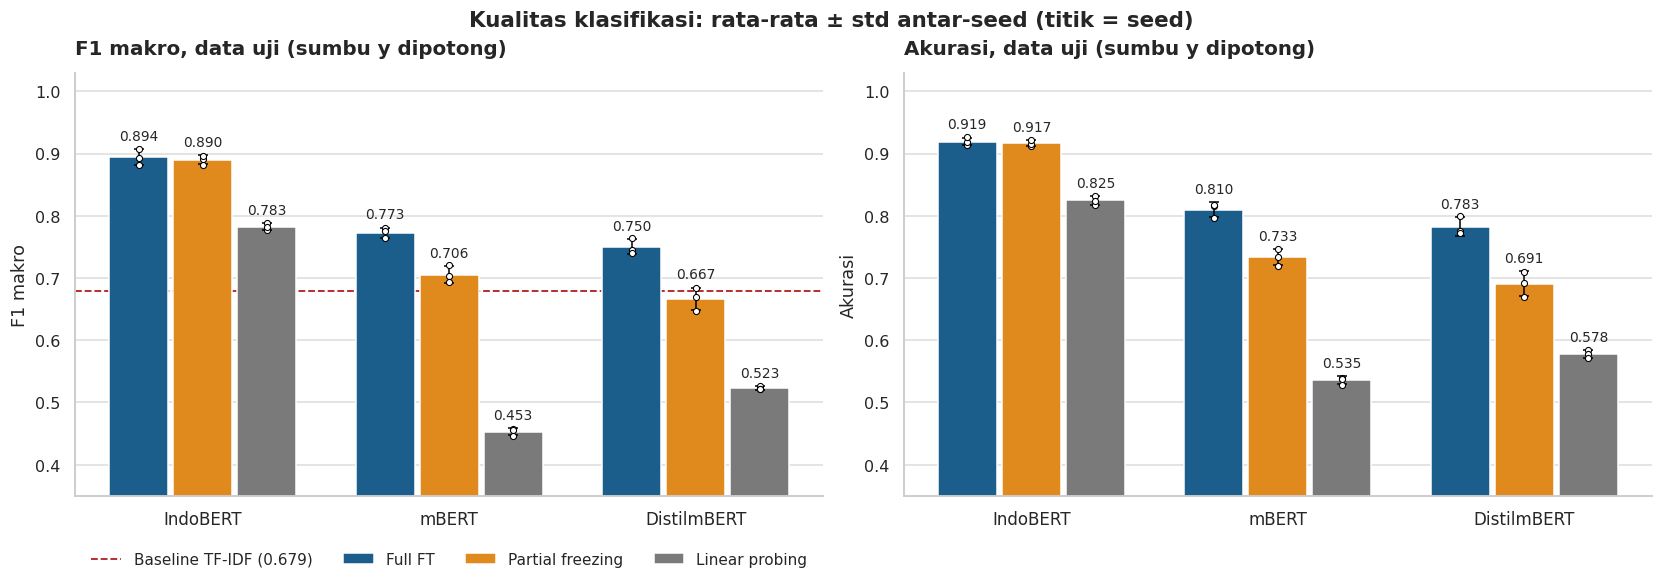

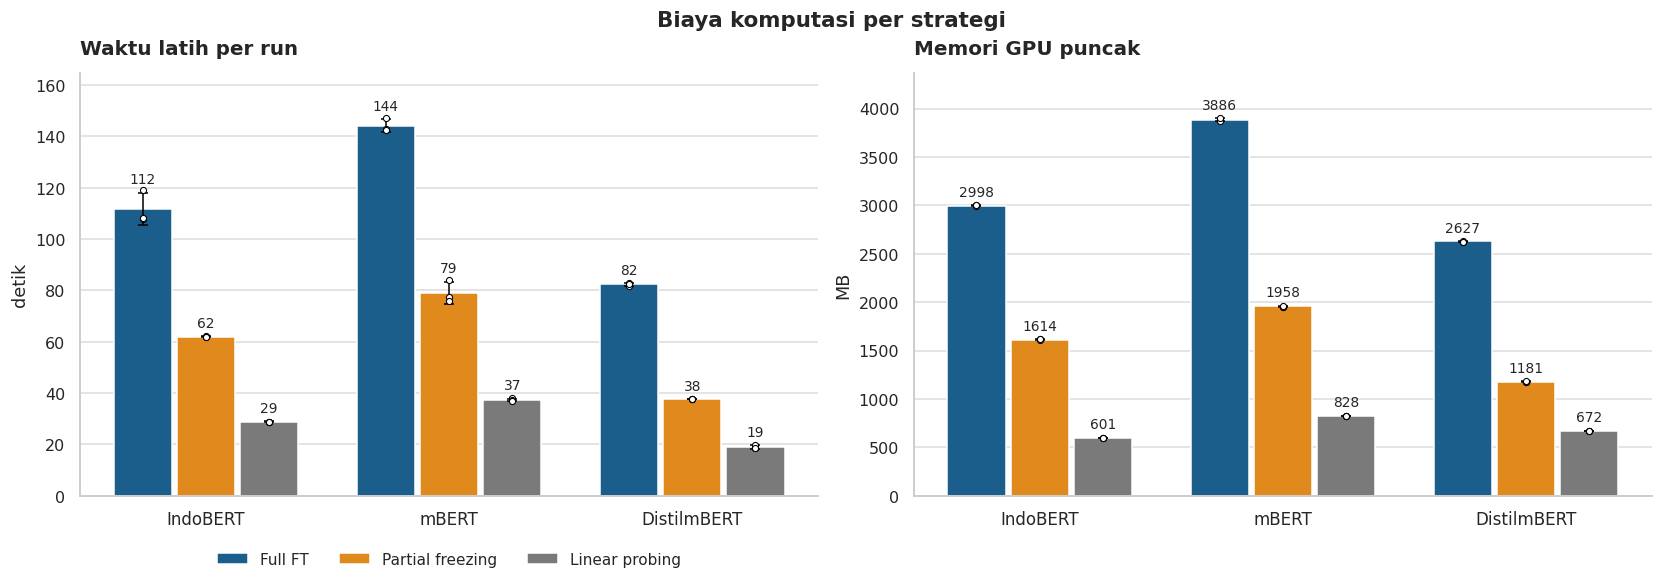

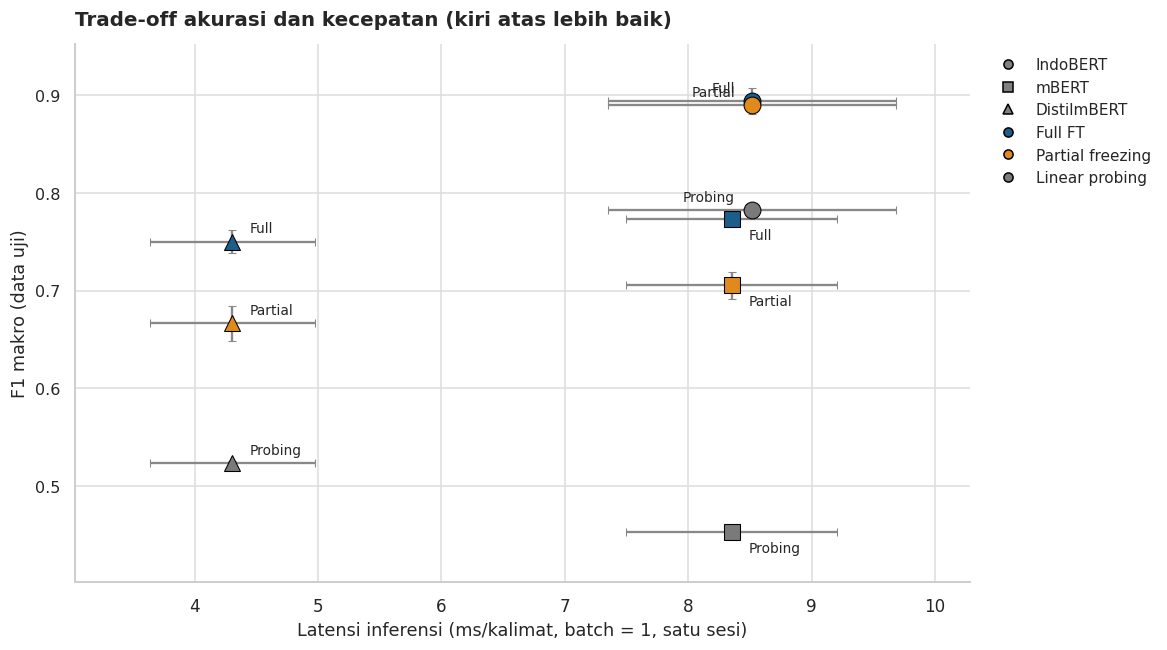

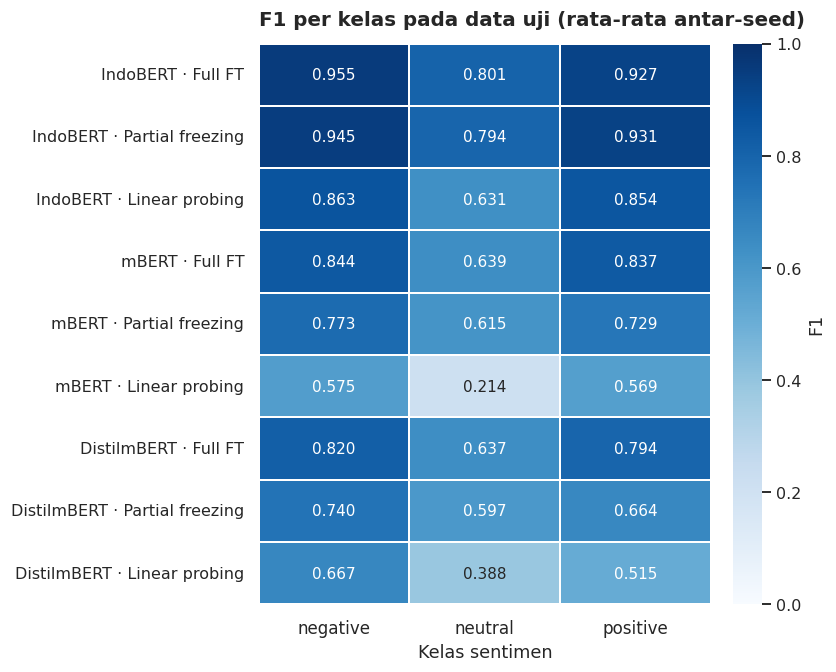

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11.5,
    "xtick.labelsize": 11, "ytick.labelsize": 10.5, "legend.fontsize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "grid.color": "#dddddd", "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})

NAMA_BB = {"indobert": "IndoBERT", "mbert": "mBERT", "distilmbert": "DistilmBERT"}
KEY_BB = {v: k for k, v in NAMA_BB.items()}
NAMA_ST = {"full": "Full FT", "partial": "Partial freezing", "probing": "Linear probing"}
WARNA = {"Full FT": "#1b5e8c", "Partial freezing": "#e08a1e", "Linear probing": "#7a7a7a"}
URUT_BB = [NAMA_BB[k] for k in CONFIG["backbones"]]
URUT_ST = [NAMA_ST[s] for s in CONFIG["strategies"]]

d = df_hasil.copy()
d["Backbone"] = d["backbone"].map(NAMA_BB)
d["Strategi"] = d["strategy"].map(NAMA_ST)
agg = d.groupby(["Backbone", "Strategi"]).agg(
    f1=("f1_macro", "mean"), f1_sd=("f1_macro", "std"),
    acc=("accuracy", "mean"), acc_sd=("accuracy", "std"),
    waktu=("train_time_s", "mean"), waktu_sd=("train_time_s", "std"),
    mem=("peak_memory_mb", "mean"), mem_sd=("peak_memory_mb", "std")).reset_index().fillna(0)

def batang_dengan_seed(ax, kolom, kolom_sd, kolom_raw, judul, ylabel, fmt):
    """Batang = rata-rata, garis = std antar-seed, titik = nilai tiap seed."""
    lebar = 0.26
    for j, st in enumerate(URUT_ST):
        for i, bb in enumerate(URUT_BB):
            baris = agg[(agg.Backbone == bb) & (agg.Strategi == st)].iloc[0]
            x = i + (j - 1) * lebar
            ax.bar(x, baris[kolom], lebar * 0.92, color=WARNA[st], label=st if i == 0 else None, zorder=2)
            ax.errorbar(x, baris[kolom], yerr=baris[kolom_sd], color="black", capsize=3, lw=1, zorder=4)
            titik = d[(d.Backbone == bb) & (d.Strategi == st)][kolom_raw]
            ax.scatter([x] * len(titik), titik, s=16, color="white", edgecolor="black", lw=0.7, zorder=5)
            ax.annotate(fmt.format(baris[kolom]), (x, baris[kolom] + baris[kolom_sd]),
                        xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9, zorder=6)
    ax.set_xticks(range(len(URUT_BB)))
    ax.set_xticklabels(URUT_BB)
    ax.set_title(judul, loc="left", pad=12)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.12)

# Gambar 1: F1 makro dan akurasi
fig1, ax = plt.subplots(1, 2, figsize=(15, 5.2), constrained_layout=True)
batang_dengan_seed(ax[0], "f1", "f1_sd", "f1_macro", "F1 makro, data uji (sumbu y dipotong)", "F1 makro", "{:.3f}")
batang_dengan_seed(ax[1], "acc", "acc_sd", "accuracy", "Akurasi, data uji (sumbu y dipotong)", "Akurasi", "{:.3f}")
bawah = max(0.0, np.floor((min(d[["f1_macro", "accuracy"]].min().min(), BASELINE_F1) - 0.05) * 20) / 20)
for a in ax:
    a.set_ylim(bawah, 1.03)
ax[0].axhline(BASELINE_F1, color="#b22222", ls="--", lw=1.2, label=f"Baseline TF-IDF ({BASELINE_F1:.3f})", zorder=1)
ax[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
fig1.suptitle("Kualitas klasifikasi: rata-rata ± std antar-seed (titik = seed)", fontsize=14, fontweight="bold")
fig1.savefig(OUTPUT_DIR / f"grafik_1_akurasi_{KODE}.png")
plt.show()

# Gambar 2: biaya komputasi
fig2, ax = plt.subplots(1, 2, figsize=(15, 5.2), constrained_layout=True)
batang_dengan_seed(ax[0], "waktu", "waktu_sd", "train_time_s", "Waktu latih per run", "detik", "{:.0f}")
batang_dengan_seed(ax[1], "mem", "mem_sd", "peak_memory_mb", "Memori GPU puncak", "MB", "{:.0f}")
ax[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
fig2.suptitle("Biaya komputasi per strategi", fontsize=14, fontweight="bold")
fig2.savefig(OUTPUT_DIR / f"grafik_2_biaya_{KODE}.png")
plt.show()

# Gambar 3: trade-off F1 vs latensi (latensi dari benchmark satu sesi)
lat_stat = df_lat.groupby("backbone").latency_ms.agg(["mean", "std"]).fillna(0)
fig3, ax = plt.subplots(figsize=(10.5, 5.8), constrained_layout=True)
tanda = {"IndoBERT": "o", "mBERT": "s", "DistilmBERT": "^"}
SINGKAT = {"Full FT": "Full", "Partial freezing": "Partial", "Linear probing": "Probing"}
GESER = {"IndoBERT": (-11, 6, "right"), "mBERT": (11, -13, "left"), "DistilmBERT": (11, 6, "left")}
for _, r in agg.iterrows():
    x, sx = lat_stat.loc[KEY_BB[r.Backbone]]
    ax.errorbar(x, r.f1, xerr=sx, yerr=r.f1_sd, fmt=tanda[r.Backbone], ms=11, color=WARNA[r.Strategi],
                mec="black", mew=0.7, ecolor="#888888", capsize=2.5, zorder=3)
    dx, dy, ha = GESER[r.Backbone]
    ax.annotate(SINGKAT[r.Strategi], (x, r.f1), xytext=(dx, dy), textcoords="offset points", fontsize=9, ha=ha)
ax.set_xlabel("Latensi inferensi (ms/kalimat, batch = 1, satu sesi)")
ax.set_ylabel("F1 makro (data uji)")
ax.set_title("Trade-off akurasi dan kecepatan (kiri atas lebih baik)", loc="left", pad=12)
from matplotlib.lines import Line2D
legenda = [Line2D([], [], marker=m, ls="", color="gray", mec="black", label=b) for b, m in tanda.items()] + \
          [Line2D([], [], marker="o", ls="", color=c, mec="black", label=s) for s, c in WARNA.items()]
ax.legend(handles=legenda, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.margins(x=0.1, y=0.1)
fig3.savefig(OUTPUT_DIR / f"grafik_3_tradeoff_{KODE}.png")
plt.show()

# Gambar 4: F1 per kelas
kelas = {"f1_negative": "negative", "f1_neutral": "neutral", "f1_positive": "positive"}
pivot = d.groupby(["Backbone", "Strategi"])[list(kelas)].mean().rename(columns=kelas)
pivot = pivot.reindex(pd.MultiIndex.from_product([URUT_BB, URUT_ST]))
pivot.index = [f"{b} · {s}" for b, s in pivot.index]
fig4, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, linewidths=1, linecolor="white",
            cbar_kws={"label": "F1"}, annot_kws={"fontsize": 10}, ax=ax)
ax.set_title("F1 per kelas pada data uji (rata-rata antar-seed)", loc="left", pad=12)
ax.set_xlabel("Kelas sentimen")
ax.set_ylabel("")
fig4.savefig(OUTPUT_DIR / f"grafik_4_f1_per_kelas_{KODE}.png")
plt.show()

## 13. Confusion Matrix

Confusion matrix digunakan untuk melihat jenis kesalahan model, yaitu kelas sentimen yang sering tertukar dengan kelas lainnya.

- **Baris** menunjukkan sentimen sebenarnya (*Actual*), sedangkan **kolom** menunjukkan hasil prediksi model (*Predicted*).
- Setiap sel menampilkan `jumlah (persentase)`. Persentase dihitung berdasarkan total setiap baris, sehingga nilai diagonal menunjukkan *recall* masing-masing kelas. Warna menggunakan skala 0–100% yang sama pada seluruh panel agar hasilnya mudah dibandingkan.
- Jumlah prediksi merupakan **rata-rata dari tiga seed** yang dibulatkan. Total setiap baris tetap mengikuti jumlah data uji, yaitu 204 *negative*, 88 *neutral*, dan 208 *positive*.
- Gambar pertama menampilkan hasil *full fine-tuning* dari ketiga backbone, sedangkan gambar kedua menampilkan seluruh sembilan kombinasi eksperimen. Seluruh prediksi diambil dari hasil yang telah disimpan selama pelatihan.

Melalui visualisasi ini, dapat dilihat kelas mana yang paling sering salah diprediksi, terutama kelas *neutral* yang memiliki jumlah sampel lebih sedikit.

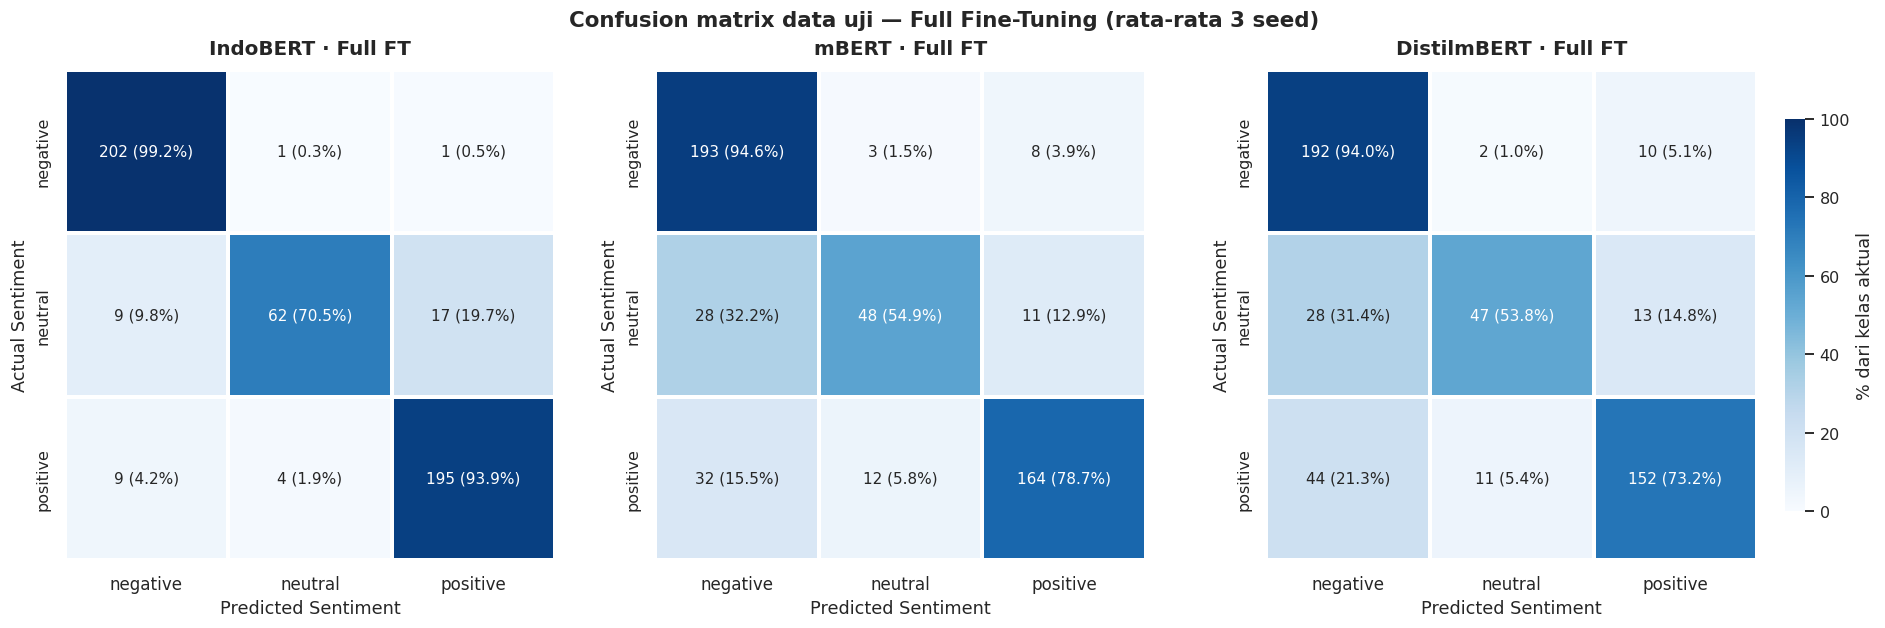

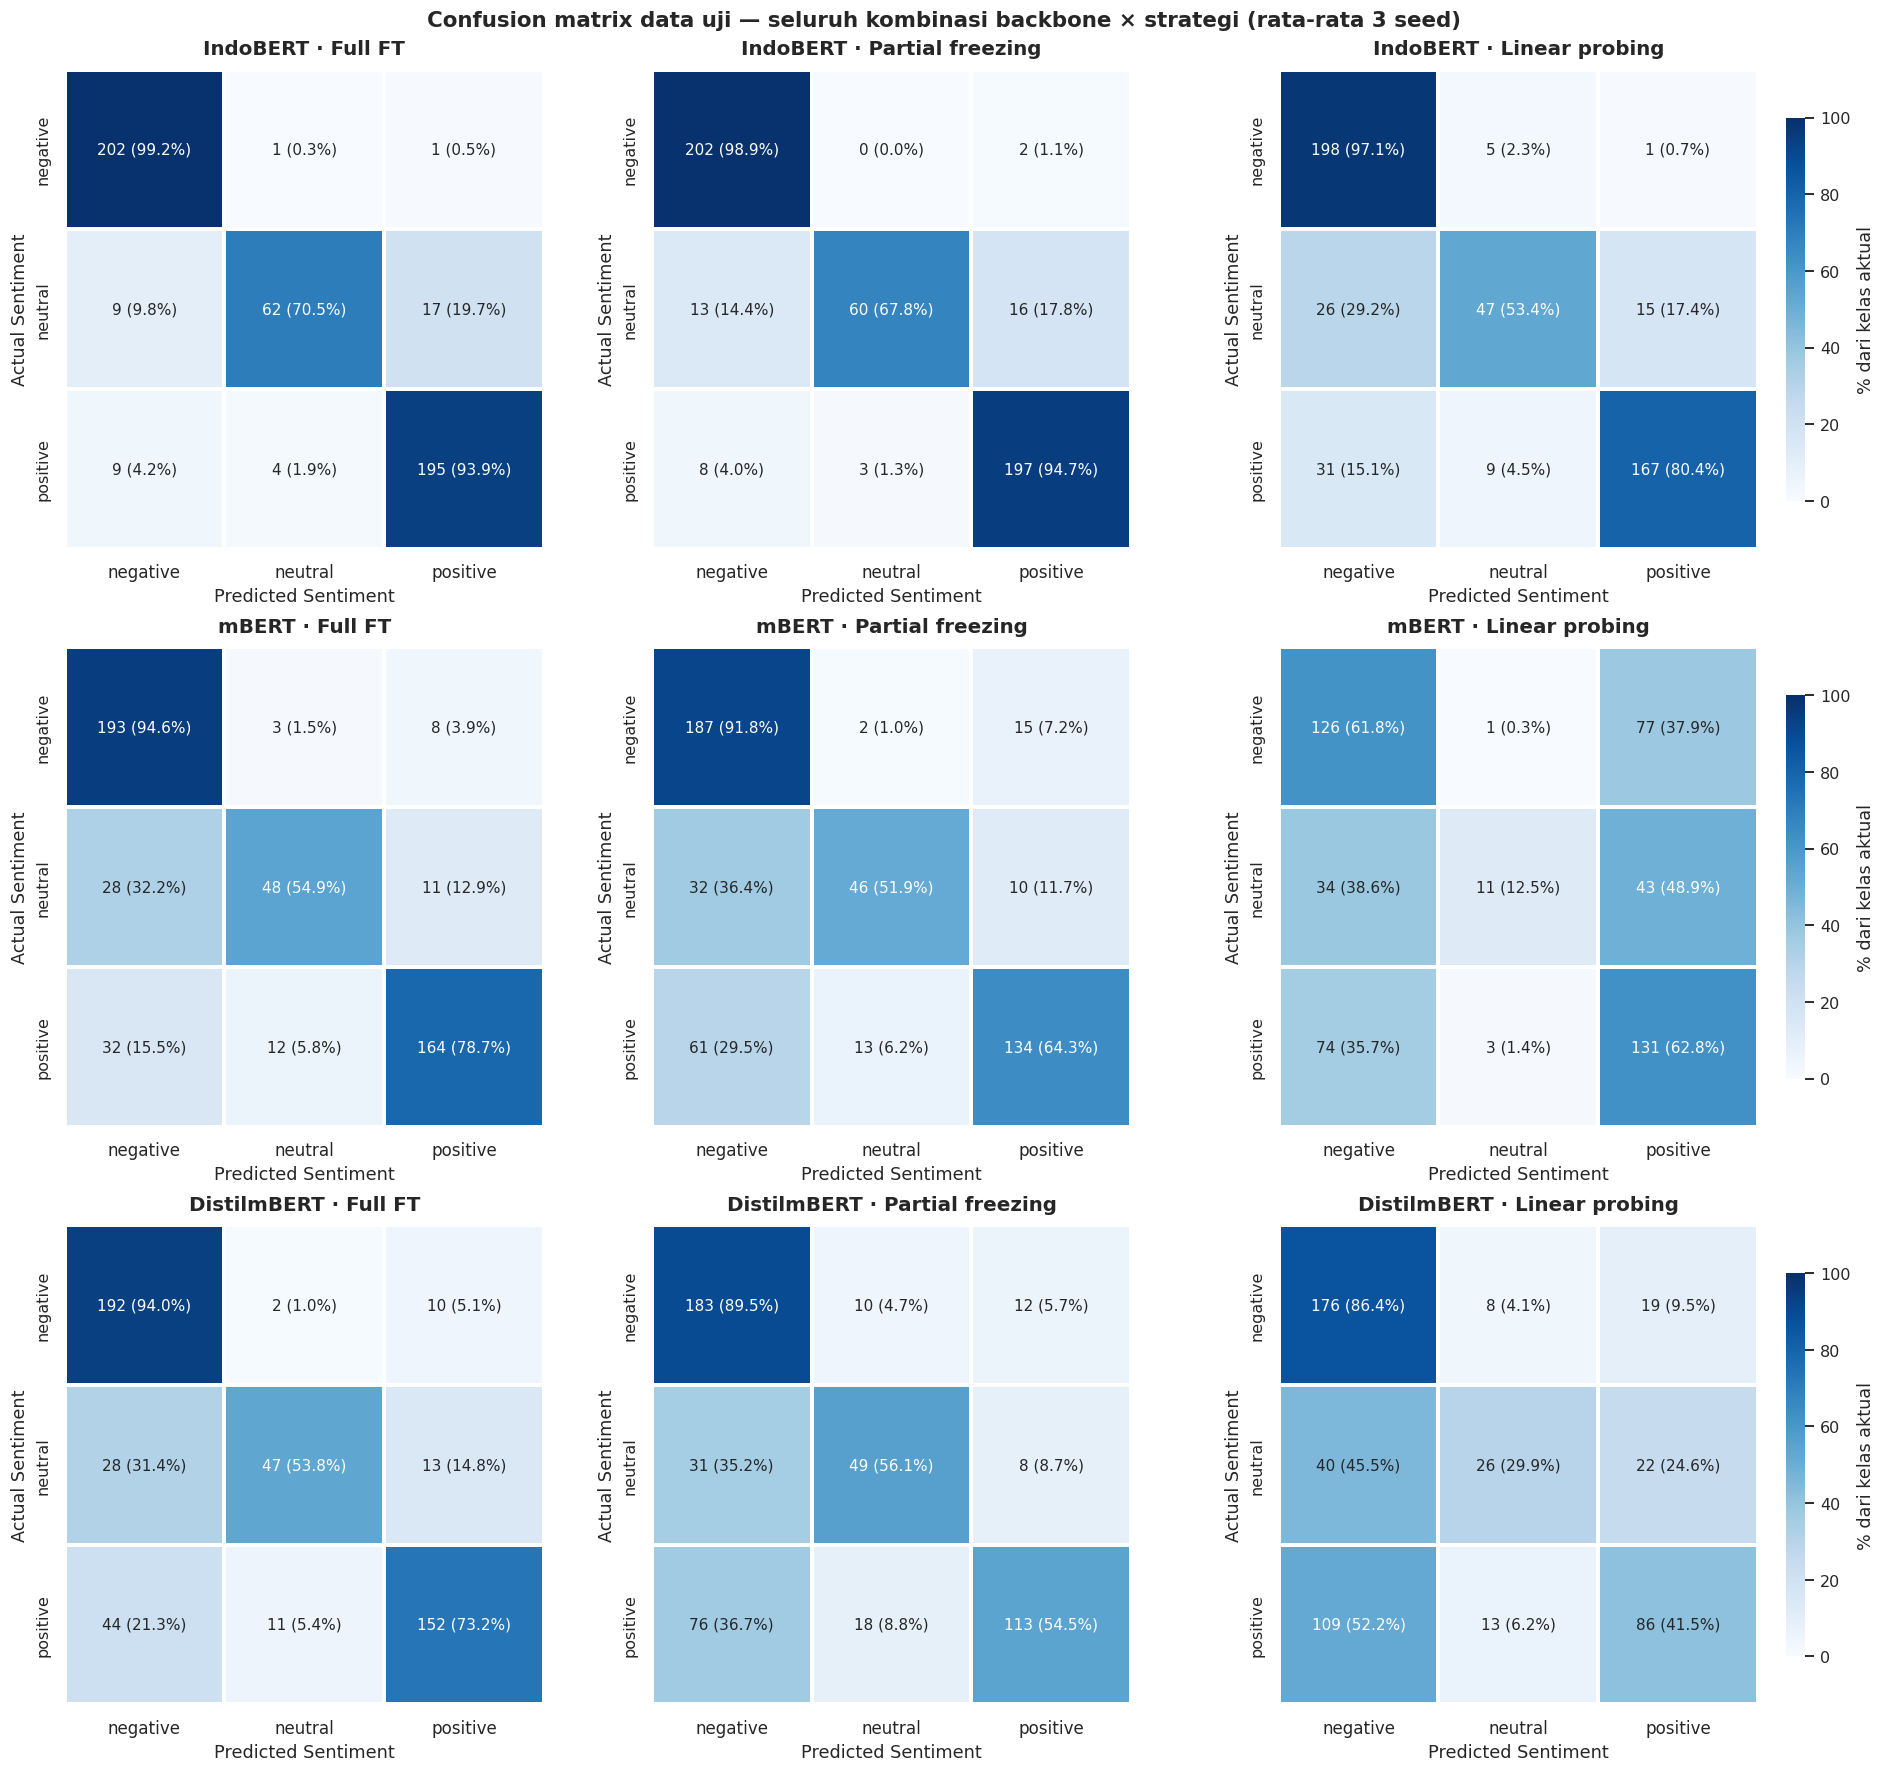

In [ ]:
df_pred = pd.read_csv(berkas_prediksi)
NAMA_KELAS = ["negative", "neutral", "positive"]

def cm_rata_seed(bb, st):
    sub = df_pred[(df_pred.backbone == bb) & (df_pred.strategy == st)]
    mats = [confusion_matrix(g.y_true, g.y_pred, labels=[0, 1, 2]) for _, g in sub.groupby("seed")]
    return np.mean(mats, axis=0)

def gambar_cm(ax, bb, st, tampil_cbar=False):
    m = cm_rata_seed(bb, st)
    pct = m / m.sum(axis=1, keepdims=True) * 100
    label = np.array([[f"{m[i, j]:.0f} ({pct[i, j]:.1f}%)" for j in range(3)] for i in range(3)])
    sns.heatmap(pct, annot=label, fmt="", cmap="Blues", vmin=0, vmax=100, linewidths=1.5, linecolor="white",
                square=True, cbar=tampil_cbar, cbar_kws={"label": "% dari kelas aktual", "shrink": 0.8},
                xticklabels=NAMA_KELAS, yticklabels=NAMA_KELAS, annot_kws={"fontsize": 10}, ax=ax)
    ax.set_title(f"{NAMA_BB[bb]} · {NAMA_ST[st]}", pad=10)
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

# Gambar 5: full fine-tuning, tiga backbone
fig5, axes = plt.subplots(1, 3, figsize=(17, 5.6), constrained_layout=True)
for k, bb in enumerate(CONFIG["backbones"]):
    gambar_cm(axes[k], bb, "full", tampil_cbar=(k == 2))
fig5.suptitle("Confusion matrix data uji — Full Fine-Tuning (rata-rata 3 seed)", fontsize=14, fontweight="bold")
fig5.savefig(OUTPUT_DIR / f"grafik_5_confusion_full_{KODE}.png")
plt.show()

# Gambar 6: seluruh kombinasi
fig6, axes = plt.subplots(3, 3, figsize=(17, 16), constrained_layout=True)
for i, bb in enumerate(CONFIG["backbones"]):
    for j, st in enumerate(CONFIG["strategies"]):
        gambar_cm(axes[i, j], bb, st, tampil_cbar=(j == 2))
fig6.suptitle("Confusion matrix data uji — seluruh kombinasi backbone × strategi (rata-rata 3 seed)",
              fontsize=14, fontweight="bold")
fig6.savefig(OUTPUT_DIR / f"grafik_6_confusion_semua_{KODE}.png")
plt.show()

## 14. Evaluasi Hipotesis H1–H3 dan Pemeriksaan Kewajaran

Setelah seluruh eksperimen selesai, ketiga hipotesis yang telah ditetapkan pada bagian rancangan dievaluasi berdasarkan hasil pengujian. Setiap hipotesis diperiksa menggunakan metrik yang sesuai dengan tujuan perbandingannya.

- **H1 (Keunggulan IndoBERT):** Membandingkan rata-rata Macro F1 IndoBERT dengan mBERT dan DistilBERT pada Full Fine-Tuning. Pengujian menggunakan uji-t Welch dan melihat apakah selisih performanya lebih besar daripada simpangan baku antar-seed.
- **H2 (Efisiensi DistilBERT):** Membandingkan waktu pelatihan pada Full Fine-Tuning dan latensi inferensi DistilBERT terhadap mBERT. Penghematan waktu diharapkan minimal 35%, dengan penurunan Macro F1 tidak lebih dari 3 poin persentase.
- **H3 (Pengaruh Pembekuan Lapisan):** Memeriksa urutan performa Full Fine-Tuning ≥ Partial Freezing > Linear Probing. Partial Freezing diharapkan mempertahankan minimal 96% Macro F1 Full Fine-Tuning, dengan penghematan waktu pelatihan dan memori GPU minimal 40%.

Hasil setiap hipotesis ditampilkan dengan status **TERDUKUNG** atau **TIDAK TERDUKUNG** sesuai hasil pengujian. Hipotesis yang tidak terpenuhi tetap dilaporkan berdasarkan hasil eksperimen. Karena pengujian hanya menggunakan tiga seed, uji-t memiliki keterbatasan dalam mendeteksi perbedaan. Oleh karena itu, nilai *p-value* juga dilihat bersama selisih rata-rata dan simpangan baku.

**Pemeriksaan Kewajaran Hasil**

Setiap kombinasi eksperimen juga dibandingkan dengan baseline TF-IDF dan tebakan acak untuk memastikan hasilnya masih masuk akal.

- **Macro F1 > 0,97:** Perlu dicurigai adanya kebocoran data. Pembagian data dan proses penghapusan duplikat perlu diperiksa kembali.
- **Macro F1 ≤ 0,40:** Performa mendekati tebakan acak (0,33), sehingga learning rate, pemetaan label, dan jumlah epoch perlu diperiksa.
- **Macro F1 di bawah baseline TF-IDF:** Perlu ditinjau kembali. Kondisi ini masih mungkin terjadi pada Linear Probing, tetapi pengaturan learning rate tetap perlu diperiksa.
- **Selain kondisi tersebut:** Hasil dianggap wajar.

In [ ]:
from scipy import stats

def _g(bb, st, kolom):
    return df_hasil[(df_hasil.backbone == bb) & (df_hasil.strategy == st)][kolom].values

R = {}
# H1: IndoBERT vs mBERT dan DistilmBERT (full FT), F1 makro
for lawan in ("mbert", "distilmbert"):
    a, b = _g("indobert", "full", "f1_macro"), _g(lawan, "full", "f1_macro")
    selisih = a.mean() - b.mean()
    if len(a) < 2 or len(b) < 2:
        R[f"H1 indobert vs {lawan}"] = (f"selisih {selisih*100:+.2f} poin (seed < 2, tidak bisa diuji)", False)
        continue
    _, p = stats.ttest_ind(a, b, equal_var=False)
    sd = max(a.std(ddof=1), b.std(ddof=1))
    R[f"H1 indobert vs {lawan}"] = (
        f"selisih {selisih*100:+.2f} poin, std maks {sd*100:.2f}, p={p:.4f}",
        bool(selisih > 0 and p < 0.05 and selisih > sd))

# H2: DistilmBERT vs mBERT; waktu latih dari full FT, latensi dari benchmark satu sesi
m, dm = "mbert", "distilmbert"
hemat_latih = 1 - _g(dm, "full", "train_time_s").mean() / _g(m, "full", "train_time_s").mean()
lat_m = df_lat[df_lat.backbone == m].latency_ms.mean()
lat_d = df_lat[df_lat.backbone == dm].latency_ms.mean()
hemat_lat = 1 - lat_d / lat_m
drop_f1 = (_g(m, "full", "f1_macro").mean() - _g(dm, "full", "f1_macro").mean()) * 100
R["H2 hemat waktu latih >=35%"] = (f"{hemat_latih*100:.1f}%", hemat_latih >= 0.35)
R["H2 hemat latensi >=35% (satu sesi)"] = (f"{hemat_lat*100:.1f}% ({lat_m:.2f} -> {lat_d:.2f} ms)", hemat_lat >= 0.35)
R["H2 penurunan F1 <=3 poin"] = (f"{drop_f1:.2f} poin", drop_f1 <= 3.0)

# H3: hierarki dan efisiensi partial freezing (per backbone)
for bb in CONFIG["backbones"]:
    f, p_, l = (_g(bb, s, "f1_macro").mean() for s in ("full", "partial", "probing"))
    R[f"H3 {bb} hierarki full>=partial>probing"] = (f"{f:.4f} / {p_:.4f} / {l:.4f}", bool(f >= p_ > l))
    R[f"H3 {bb} partial>=96% F1 full"] = (f"{p_/f*100:.1f}%", p_ / f >= 0.96)
    hw = 1 - _g(bb, "partial", "train_time_s").mean() / _g(bb, "full", "train_time_s").mean()
    hm = 1 - _g(bb, "partial", "peak_memory_mb").mean() / _g(bb, "full", "peak_memory_mb").mean()
    R[f"H3 {bb} hemat waktu >=40%"] = (f"{hw*100:.1f}%", hw >= 0.40)
    R[f"H3 {bb} hemat memori >=40%"] = (f"{hm*100:.1f}%", hm >= 0.40)

tabel_hipotesis = pd.DataFrame([(k, v[0], "TERDUKUNG" if v[1] else "TIDAK TERDUKUNG") for k, v in R.items()],
                               columns=["pengujian", "nilai terukur", "status"])
simpan_csv_atomik(tabel_hipotesis, OUTPUT_DIR / f"evaluasi_hipotesis_{KODE}.csv")
display(tabel_hipotesis)

# Pemeriksaan kewajaran terhadap pembanding yang sah
def status_wajar(f1):
    if f1 > 0.97:
        return "curiga kebocoran data"
    if f1 <= 0.40:
        return "mendekati tebakan acak: cek lr/label/epoch"
    if f1 < BASELINE_F1:
        return "di bawah baseline TF-IDF: cek learning rate"
    return "wajar"

cek = df_hasil.groupby(["backbone", "strategy"]).f1_macro.agg(["mean", "std"]).reset_index()
cek["selisih_vs_tfidf_poin"] = (cek["mean"] - BASELINE_F1) * 100
cek["status"] = cek["mean"].map(status_wajar)
cek = cek.rename(columns={"mean": "f1_macro_mean", "std": "f1_macro_std"})
simpan_csv_atomik(cek, OUTPUT_DIR / f"cek_kewajaran_smsa_{KODE}.csv")
print(f"Pembanding: baseline TF-IDF = {BASELINE_F1:.4f} | tebakan acak ≈ 0.33")
display(cek.round(4))

,pengujian,nilai terukur,status
0,H1 indobert vs mbert,"selisih +12.11 poin, std maks 1.30, p=0.0005",TERDUKUNG
1,H1 indobert vs distilmbert,"selisih +14.40 poin, std maks 1.30, p=0.0002",TERDUKUNG
2,H2 hemat waktu latih >=35%,42.8%,TERDUKUNG
3,H2 hemat latensi >=35% (satu sesi),48.4% (8.35 -> 4.31 ms),TERDUKUNG
4,H2 penurunan F1 <=3 poin,2.29 poin,TERDUKUNG
5,H3 indobert hierarki full>=partial>probing,0.8942 / 0.8901 / 0.7826,TERDUKUNG
6,H3 indobert partial>=96% F1 full,99.5%,TERDUKUNG
7,H3 indobert hemat waktu >=40%,44.6%,TERDUKUNG
8,H3 indobert hemat memori >=40%,46.2%,TERDUKUNG
9,H3 mbert hierarki full>=partial>probing,0.7730 / 0.7055 / 0.4527,TERDUKUNG


Pembanding: baseline TF-IDF = 0.6786 | tebakan acak ≈ 0.33


,backbone,strategy,f1_macro_mean,f1_macro_std,selisih_vs_tfidf_poin,status
0,distilmbert,full,0.7501,0.0121,7.1534,wajar
1,distilmbert,partial,0.6668,0.0180,-1.1847,di bawah baseline TF-IDF: cek learning rate
2,distilmbert,probing,0.5231,0.0026,-15.5476,di bawah baseline TF-IDF: cek learning rate
3,indobert,full,0.8942,0.0130,21.5582,wajar
4,indobert,partial,0.8901,0.0074,21.1528,wajar
5,indobert,probing,0.7826,0.0060,10.4048,wajar
6,mbert,full,0.7730,0.0081,9.4446,wajar
7,mbert,partial,0.7055,0.0138,2.6947,wajar
8,mbert,probing,0.4527,0.0056,-22.5881,di bawah baseline TF-IDF: cek learning rate


### Pembahasan Hasil Hipotesis dan Kewajaran

**H1 terdukung.** Pada full fine-tuning, IndoBERT mencapai F1 makro **0,8942 ± 0,0130**, dibanding mBERT **0,7730 ± 0,0081** dan
DistilmBERT **0,7501 ± 0,0121**. Selisihnya +12,11 poin (p = 0,0005) dan +14,40 poin (p = 0,0002), kira-kira sepuluh kali simpangan baku
antar-seed terbesar (1,30 poin). Keunggulan ini bukan kebetulan seed.

**H2 terdukung.** Terhadap mBERT, DistilmBERT menghemat waktu latih **42,8%** (144,1 → 82,4 detik) dan latensi **48,4%** (8,35 → 4,31 ms/kalimat),
dengan penurunan F1 makro **2,29 poin**, masih di bawah batas 3 poin. Penurunan ini tetap lebih besar dari simpangan antar-seed (1,21 poin),
jadi DistilmBERT memang sedikit lebih lemah, hanya masih dalam toleransi yang ditetapkan.

**H3 hanya terdukung pada IndoBERT.** Urutan full ≥ partial > probing berlaku di ketiga backbone, dan partial freezing selalu menghemat waktu
latih (44,6–54,4%) serta memori GPU (46,2–55,1%) di atas 40%. Syarat partial ≥ 96% F1 full hanya dipenuhi IndoBERT (**99,5%**). mBERT (91,3%)
dan DistilmBERT (88,9%) gagal. Penjelasan yang paling masuk akal: lapis bawah IndoBERT sudah dilatih pada teks Indonesia sehingga aman
dibekukan, sedangkan model multibahasa masih perlu menyesuaikan lapis bawahnya dengan Bahasa Indonesia.

**Pemeriksaan kewajaran.** Tidak ada konfigurasi dengan F1 > 0,97, jadi tidak ada indikasi kebocoran data. Pembersihan data juga memastikan
tidak ada teks latih yang muncul di validasi atau uji. Baseline TF-IDF (data latih penuh) memperoleh F1 makro **0,6786**, sedikit di bawah
patokan lembar soal (sekitar 0,73) karena regresi logistik dipakai dengan pengaturan bawaan tanpa penyetelan. Tiga konfigurasi berada di bawah baseline ini:

- **DistilmBERT partial (0,6668 ± 0,0180):** hanya 1,18 poin di bawah baseline, lebih kecil dari simpangan antar-seed (1,80 poin),
  jadi secara praktis **setara** dengan baseline.
- **mBERT probing (0,4527 ± 0,0056)** dan **DistilmBERT probing (0,5231 ± 0,0026):** jauh di bawah baseline. Sesuai lembar soal,
  learning rate diperiksa lewat kurva F1 validasi per epoch di CSV hasil. Pada mBERT probing kurvanya **naik terus** (contoh seed 42:
  0,484 → 0,569 → 0,633 → 0,654), tanpa osilasi atau penurunan yang menandakan learning rate terlalu besar. Artinya head belum konvergen
  dalam 4 epoch (sekitar 630 langkah) di atas fitur multibahasa yang dibekukan, bukan pelatihan yang gagal. Protokol tidak diubah di tengah
  eksperimen agar semua run tetap sebanding; hal ini dicatat sebagai keterbatasan.

**Selisih validasi dan uji.** Skor uji lebih rendah dari skor validasi, terutama pada model multibahasa: IndoBERT full turun 1,8 poin
(0,9126 → 0,8942), mBERT full 8,6 poin, dan DistilmBERT full 9,2 poin. Penyebabnya adalah sebaran uji yang berbeda: porsi *neutral* naik dari
10,4% menjadi 17,6% dan *positive* turun dari 58,4% menjadi 41,6%. Confusion matrix menunjukkan model multibahasa paling sering salah
mengklasifikasikan kalimat *neutral* sebagai *negative* (32,2% pada mBERT dan 31,4% pada DistilmBERT, dibanding 9,8% pada IndoBERT),
sehingga recall *neutral* mereka hanya sekitar 54–55%, sedangkan IndoBERT 70,5%.

**Keterbatasan.** Sebagian besar run mencapai F1 validasi terbaik di epoch ke-4, jadi model masih bisa membaik dengan epoch lebih banyak.
Tiga seed membuat uji-t berdaya rendah sehingga p-value dibaca sebagai indikasi. Latensi IndoBERT dan mBERT (8,51 vs 8,35 ms) berada dalam
rentang simpangan pengukuran, sehingga keduanya dianggap setara.

## 15. Tiga Pertanyaan Riset Wajib

Sesuai lembar soal, terdapat tiga pertanyaan yang harus dijawab pada presentasi akhir. Ketiganya berfokus pada perbandingan performa model, efisiensi komputasi, dan pemilihan konfigurasi terbaik.

| | Pertanyaan | Informasi yang Harus Disertakan |
|:---:|:---|:---|
| **Q1** | Backbone mana yang memberikan trade-off terbaik antara akurasi dan efisiensi untuk klasifikasi sentimen? | Macro F1 ± SD, waktu pelatihan, latensi inferensi, dan jumlah parameter. |
| **Q2** | Apakah strategi yang lebih hemat komputasi (Linear Probing dan Partial Freezing) mampu bersaing dengan Full Fine-Tuning? | Selisih performa terhadap variasi antar-seed untuk melihat apakah perbedaannya cukup berarti. |
| **Q3** | Kombinasi model dan strategi mana yang paling layak direkomendasikan? | Alasan pemilihan berdasarkan anggaran komputasi, kecepatan inferensi, dan hasil pengujian. |

**Kriteria Pemilihan**

Kriteria berikut ditetapkan sebelum hasil eksperimen dilihat dan disimpan dalam variabel `KRITERIA` agar pemilihan model tidak hanya didasarkan pada hasil yang paling tinggi.

- **Syarat Minimum:** Model harus memiliki status kewajaran "wajar", yaitu Macro F1 berada di atas baseline TF-IDF dan tidak menunjukkan indikasi kebocoran data.
- **Selisih Bermakna:** Perbedaan rata-rata Macro F1 antara dua konfigurasi dianggap bermakna jika melebihi simpangan baku terbesar dari keduanya. Jika tidak, kedua konfigurasi dianggap belum menunjukkan perbedaan yang jelas.
- **Skenario A — Akurasi Utama:** Memilih konfigurasi dengan Macro F1 tertinggi.
- **Skenario B — Anggaran Pelatihan Terbatas:** Memilih konfigurasi dengan waktu pelatihan paling singkat, selama Macro F1 tidak lebih dari 2 poin di bawah nilai terbaik.
- **Skenario C — Inferensi Cepat:** Memilih konfigurasi dengan latensi terendah, selama Macro F1 tidak lebih dari 4 poin di bawah nilai terbaik.
- **Keterjelasan Hasil:** Setiap rekomendasi harus didukung oleh angka yang tercatat dalam tabel hasil dan CSV eksperimen.

Selanjutnya, seluruh angka yang dibutuhkan untuk menjawab ketiga pertanyaan tersebut dihitung dari CSV hasil eksperimen. Dengan demikian, setiap perbandingan dan rekomendasi dapat ditelusuri kembali ke hasil pengujian.

In [ ]:
KRITERIA = {"toleransi_skenario_B_poin": 2.0, "toleransi_skenario_C_poin": 4.0}

lat_mean = df_lat.groupby("backbone").latency_ms.mean()
lat_std = df_lat.groupby("backbone").latency_ms.std()
ra = rekap_agregat.set_index(["backbone", "strategy"])

# ---------- Q1: trade-off antar-backbone (full fine-tuning, protokol identik)
q1 = pd.DataFrame([{
    "backbone": NAMA_BB[bb],
    "F1 makro ± SD": f"{ra.loc[(bb, 'full'), 'f1_macro_mean']:.4f} ± {ra.loc[(bb, 'full'), 'f1_macro_std']:.4f}",
    "akurasi": round(ra.loc[(bb, 'full'), 'accuracy_mean'], 4),
    "waktu latih (s)": round(ra.loc[(bb, 'full'), 'train_time_s_mean'], 1),
    "latensi (ms/kalimat)": f"{lat_mean[bb]:.2f} ± {lat_std[bb]:.2f}",
    "parameter total (juta)": round(ra.loc[(bb, 'full'), 'total_params'] / 1e6, 1),
    "memori puncak (MB)": round(ra.loc[(bb, 'full'), 'peak_memory_mb_mean']),
} for bb in CONFIG["backbones"]])
print("Q1 - Perbandingan backbone (full fine-tuning, data uji)")
display(q1)

# ---------- Q2: strategi hemat vs full, selisih dibandingkan dengan simpangan antar-seed
baris_q2 = []
for bb in CONFIG["backbones"]:
    f_full = _g(bb, "full", "f1_macro")
    for st in ("partial", "probing"):
        f_st = _g(bb, st, "f1_macro")
        selisih = (f_full.mean() - f_st.mean()) * 100
        sd_maks = max(f_full.std(ddof=1), f_st.std(ddof=1)) * 100
        _, p = stats.ttest_ind(f_full, f_st, equal_var=False)
        baris_q2.append({
            "backbone": NAMA_BB[bb], "strategi": NAMA_ST[st],
            "F1 ± SD": f"{f_st.mean():.4f} ± {f_st.std(ddof=1):.4f}",
            "tertinggal dari full (poin)": round(selisih, 2),
            "SD antar-seed maks (poin)": round(sd_maks, 2),
            "p (Welch)": round(p, 4),
            "kesimpulan": "beda bermakna" if abs(selisih) > sd_maks else "belum beda (setara)",
            "% F1 full": round(f_st.mean() / f_full.mean() * 100, 1),
            "hemat waktu latih": f"{(1 - _g(bb, st, 'train_time_s').mean() / _g(bb, 'full', 'train_time_s').mean()) * 100:.1f}%",
            "hemat memori": f"{(1 - _g(bb, st, 'peak_memory_mb').mean() / _g(bb, 'full', 'peak_memory_mb').mean()) * 100:.1f}%",
            "parameter dilatih": f"{ra.loc[(bb, st), 'trainable_params'] / ra.loc[(bb, st), 'total_params'] * 100:.2f}%",
            "vs TF-IDF (poin)": round((f_st.mean() - BASELINE_F1) * 100, 2),
        })
q2 = pd.DataFrame(baris_q2)
print("\nQ2 - Strategi hemat komputasi dibanding full fine-tuning")
display(q2)

# ---------- Q3: rekomendasi berdasarkan kriteria yang sudah dikunci
kand = rekap_agregat.copy()
kand["latency"] = kand["backbone"].map(lat_mean)
kand["status"] = kand["f1_macro_mean"].map(status_wajar)
if (kand["status"] == "wajar").any():
    kand = kand[kand["status"] == "wajar"]
else:
    print("[PERINGATAN] Tidak ada konfigurasi berstatus wajar; rekomendasi dihitung dari semua konfigurasi.")
terbaik = kand["f1_macro_mean"].max()

def pilih(df, kolom):
    r = df.sort_values([kolom, "f1_macro_mean"], ascending=[True, False]).iloc[0]
    return r

rek = {
    "A. akurasi utama": kand.sort_values("f1_macro_mean", ascending=False).iloc[0],
    "B. anggaran latih terbatas": pilih(kand[kand.f1_macro_mean >= terbaik - KRITERIA["toleransi_skenario_B_poin"] / 100], "train_time_s_mean"),
    "C. inferensi cepat": pilih(kand[kand.f1_macro_mean >= terbaik - KRITERIA["toleransi_skenario_C_poin"] / 100], "latency"),
}
q3 = pd.DataFrame([{
    "skenario": s, "konfigurasi": f"{NAMA_BB[r.backbone]} + {NAMA_ST[r.strategy]}",
    "F1 makro ± SD": f"{r.f1_macro_mean:.4f} ± {r.f1_macro_std:.4f}",
    "selisih dari terbaik (poin)": round((terbaik - r.f1_macro_mean) * 100, 2),
    "waktu latih (s)": round(r.train_time_s_mean, 1),
    "memori (MB)": round(r.peak_memory_mb_mean),
    "latensi (ms)": round(r.latency, 2),
} for s, r in rek.items()])
print(f"\nQ3 - Rekomendasi per skenario (kandidat: status wajar; F1 terbaik = {terbaik:.4f})")
display(q3)
q3.to_csv(OUTPUT_DIR / f"rekomendasi_smsa_{KODE}.csv", index=False)

Q1 - Perbandingan backbone (full fine-tuning, data uji)


,backbone,F1 makro ± SD,akurasi,waktu latih (s),latensi (ms/kalimat),parameter total (juta),memori puncak (MB)
0,IndoBERT,0.8942 ± 0.0130,0.9193,111.8,8.51 ± 1.17,124.4,2998
1,mBERT,0.7730 ± 0.0081,0.8100,144.1,8.35 ± 0.86,177.9,3886
2,DistilmBERT,0.7501 ± 0.0121,0.7827,82.4,4.31 ± 0.67,135.3,2627



Q2 - Strategi hemat komputasi dibanding full fine-tuning


,backbone,strategi,F1 ± SD,tertinggal dari full (poin),SD antar-seed maks (poin),p (Welch),kesimpulan,% F1 full,hemat waktu latih,hemat memori,parameter dilatih,vs TF-IDF (poin)
0,IndoBERT,Partial freezing,0.8901 ± 0.0074,0.41,1.30,0.6692,belum beda (setara),99.5,44.6%,46.2%,34.65%,21.15
1,IndoBERT,Linear probing,0.7826 ± 0.0060,11.15,1.30,0.0012,beda bermakna,87.5,74.2%,80.0%,0.00%,10.40
2,mBERT,Partial freezing,0.7055 ± 0.0138,6.75,1.38,0.0041,beda bermakna,91.3,45.1%,49.6%,24.24%,2.69
3,mBERT,Linear probing,0.4527 ± 0.0056,32.03,0.81,0.0000,beda bermakna,58.6,74.1%,78.7%,0.00%,-22.59
4,DistilmBERT,Partial freezing,0.6668 ± 0.0180,8.34,1.80,0.0042,beda bermakna,88.9,54.4%,55.1%,16.15%,-1.18
5,DistilmBERT,Linear probing,0.5231 ± 0.0026,22.70,1.21,0.0006,beda bermakna,69.7,76.9%,74.4%,0.44%,-15.55



Q3 - Rekomendasi per skenario (kandidat: status wajar; F1 terbaik = 0.8942)


,skenario,konfigurasi,F1 makro ± SD,selisih dari terbaik (poin),waktu latih (s),memori (MB),latensi (ms)
0,A. akurasi utama,IndoBERT + Full FT,0.8942 ± 0.0130,0.00,111.8,2998,8.51
1,B. anggaran latih terbatas,IndoBERT + Partial freezing,0.8901 ± 0.0074,0.41,61.9,1614,8.51
2,C. inferensi cepat,IndoBERT + Full FT,0.8942 ± 0.0130,0.00,111.8,2998,8.51


### Jawaban Pertanyaan Riset

Seluruh angka berasal dari tabel Q1–Q3 di atas dan `rekap_agregat_smsa_94fade.csv` (rata-rata ± SD dari 3 seed, data uji resmi 500 kalimat).

**Q1. Backbone mana yang memberi trade-off akurasi-vs-efisiensi terbaik?**

**IndoBERT.** Pada protokol yang sama (full fine-tuning):

| Backbone | F1 makro ± SD | Waktu latih | Latensi | Parameter |
|:---|:---:|:---:|:---:|:---:|
| IndoBERT | **0,8942 ± 0,0130** | 111,8 s | 8,51 ± 1,17 ms | 124,4 juta |
| mBERT | 0,7730 ± 0,0081 | 144,1 s | 8,35 ± 0,86 ms | 177,9 juta |
| DistilmBERT | 0,7501 ± 0,0121 | **82,4 s** | **4,31 ± 0,67 ms** | 135,3 juta |

IndoBERT mengungguli mBERT di semua sisi. F1-nya 12,11 poin lebih tinggi, waktu latihnya 22% lebih singkat, memorinya lebih kecil (2.998 vs 3.886 MB),
dan jumlah parameternya lebih sedikit. Latensi keduanya setara karena selisih 0,16 ms masih di dalam simpangan pengukuran.
DistilmBERT memang paling efisien: latensinya sekitar setengah IndoBERT dan waktu latihnya 26% lebih singkat. Tetapi DistilmBERT kehilangan
14,40 poin F1, kira-kira sebelas kali simpangan antar-seed, dan recall kelas *neutral*-nya hanya 53,8% dibanding 70,5% pada IndoBERT. Penghematan
4,2 ms per kalimat tidak sebanding dengan penurunan kualitas sebesar itu, sehingga trade-off terbaik ada pada IndoBERT. Keunggulannya
berasal dari kecocokan bahasa: IndoBERT dilatih pada korpus Indonesia, sedangkan dua model lain membagi kapasitas kosakatanya untuk ratusan bahasa.

**Q2. Apakah strategi hemat komputasi cukup kompetitif dibanding full fine-tuning?**

**Hanya partial freezing pada IndoBERT yang kompetitif.** Selisih tiap strategi dibandingkan dengan simpangan antar-seed:

- **IndoBERT partial:** 0,8901 ± 0,0074, tertinggal **0,41 poin**, lebih kecil dari simpangan antar-seed 1,30 poin (p = 0,67). Hasilnya
  **belum beda** dari full fine-tuning, padahal waktu latihnya 44,6% lebih singkat, memorinya 46,2% lebih kecil, dan hanya 34,65% parameter yang dilatih.
- **mBERT partial** (−6,75 poin) dan **DistilmBERT partial** (−8,34 poin) tertinggal jauh melebihi simpangannya (1,38 dan 1,80 poin),
  jadi **beda bermakna**. DistilmBERT partial bahkan setara dengan baseline TF-IDF.
- **Linear probing** paling hemat (waktu latih 74–77% lebih singkat, memori 74–80% lebih kecil), tetapi tertinggal **11,15 poin** (IndoBERT),
  **32,03 poin** (mBERT), dan **22,70 poin** (DistilmBERT), semuanya bermakna. Probing IndoBERT masih 10,4 poin di atas baseline TF-IDF, sedangkan probing
  mBERT dan DistilmBERT berada di bawahnya.

Jadi strategi hemat hanya kompetitif bila representasi backbone yang dibekukan sudah cocok dengan bahasa data. Pada model multibahasa,
pembekuan lapis membuang kemampuan adaptasi yang justru dibutuhkan.

**Q3. Kombinasi apa yang direkomendasikan, dan mengapa?**

Kriteria yang ditetapkan sebelum melihat hasil: lolos pemeriksaan kewajaran, selisih dianggap bermakna hanya bila melebihi simpangan
antar-seed, lalu dipilih menurut tiga skenario: akurasi utama, anggaran latih terbatas (toleransi 2 poin), dan inferensi cepat (toleransi 4 poin).

| Skenario | Hasil kriteria | F1 makro ± SD | Waktu latih | Memori | Latensi |
|:---|:---|:---:|:---:|:---:|:---:|
| A. Akurasi utama | IndoBERT + Full FT | 0,8942 ± 0,0130 | 111,8 s | 2.998 MB | 8,51 ms |
| B. Anggaran latih terbatas | IndoBERT + Partial freezing | 0,8901 ± 0,0074 | 61,9 s | 1.614 MB | 8,51 ms |
| C. Inferensi cepat | IndoBERT + Full FT | 0,8942 ± 0,0130 | 111,8 s | 2.998 MB | 8,51 ms |

**Rekomendasi kami: IndoBERT + partial freezing.** Alasannya:

- **Akurasi:** F1-nya belum beda dari konfigurasi terbaik (selisih 0,41 poin, lebih kecil dari simpangan 1,30 poin).
- **Anggaran komputasi:** waktu latih hampir separuh (61,9 vs 111,8 detik) dan memori GPU 1,6 GB dibanding 3,0 GB, sehingga pelatihan ulang
  berkala jauh lebih murah dan muat di GPU kecil.
- **Kecepatan inferensi:** latensinya sama dengan full fine-tuning (8,51 ms/kalimat, sekitar 117 kalimat per detik pada T4 dengan batch 1),
  karena arsitekturnya identik.
- **Keterjelasan:** setiap alasan dapat ditelusuri ke angka di tabel. Dibanding mBERT dan DistilmBERT, model ini juga paling jarang salah
  menggolongkan kalimat *neutral* sebagai *negative*.

Skenario C tidak memilih DistilmBERT karena F1-nya 14,40 poin di bawah terbaik, jauh di luar toleransi 4 poin. DistilmBERT full fine-tuning
hanya layak bila ada batas latensi ketat di bawah 5 ms per kalimat. Konsekuensinya harus diterima: F1 makro turun ke 0,7501 dan sekitar
separuh kalimat *neutral* salah klasifikasi.

## 16. Berkas Keluaran dan Pengumpulan

Berkas berikut dibuat otomatis di `MyDrive/Studio3_NLP/output/` (kode konfigurasi run ini: `94fade`):

| Berkas | Isi |
|:---|:---|
| `hasil_smsa_94fade.csv` | satu baris per run (27 baris) dengan seluruh metrik pada data uji, epoch terbaik, dan F1 validasi per epoch |
| `rekap_agregat_smsa_94fade.csv` | rata-rata ± std per kombinasi backbone × strategi |
| `prediksi_smsa_94fade.csv` | prediksi data uji tiap run, sumber confusion matrix |
| `latensi_sesi_94fade.csv` | benchmark latensi satu sesi |
| `baseline_tfidf_smsa_94fade.csv` | baseline TF-IDF, tebakan acak, dan kelas mayoritas pada data uji |
| `subset_latih_smsa_94fade.csv` | 5.000 kalimat latih yang dipakai seluruh run |
| `evaluasi_hipotesis_94fade.csv` | status H1–H3 |
| `cek_kewajaran_smsa_94fade.csv` | posisi tiap kombinasi terhadap baseline TF-IDF dan tebakan acak |
| `rekomendasi_smsa_94fade.csv` | rekomendasi per skenario untuk Q3 |
| `grafik_1` … `grafik_6` (PNG) | visualisasi performa, biaya, trade-off, F1 per kelas, dan confusion matrix |

**Yang dikumpulkan (lembar soal):**

1. **Tautan notebook** Colab/Kaggle yang disetel *Public / Anyone with the link can view*.
2. **PDF cadangan** notebook yang sudah dijalankan penuh, dengan nama `STUDIO3_Kelompok[X]_[Anggota1]_[Anggota2].pdf`.
3. **Berkas hasil** `hasil_smsa_94fade.csv` dan `rekap_agregat_smsa_94fade.csv`.


In [19]:
# EKSPOR_PDF_CELL  (penanda: cell ini disembunyikan dari PDF)
import datetime, re, shutil, subprocess
from pathlib import Path
import nbformat

# ---- isi dulu ----
KELOMPOK = "11 - Yolo"
ANGGOTA = [("Sigit Kurnia Hartawan", "123140033"),
           ("Muhammad Romadhon Santoso", "123140031")]
NAMA_NOTEBOOK = "Studio_Proyek_3_NLP.ipynb"
# ------------------

NAMA_PDF = f"STUDIO3_Kelompok{KELOMPOK.split()[0]}_" + "_".join(re.sub(r"\s+", "_", n) for n, _ in ANGGOTA)

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

# 1. Cari notebook di Drive (File > Simpan dulu supaya semua output ikut tersimpan)
akar = Path("/content/drive/MyDrive")
kandidat = list((akar / "Colab Notebooks").glob(NAMA_NOTEBOOK)) or list(akar.rglob(NAMA_NOTEBOOK))
assert kandidat, "Notebook tidak ditemukan di Drive. Pastikan sudah File > Simpan."
sumber = max(kandidat, key=lambda p: p.stat().st_mtime)
print("Notebook sumber:", sumber)

# 2. Salin ke folder kerja, bersihkan, lalu tulis ulang dengan nama aman
kerja = Path("/content/export")
shutil.rmtree(kerja, ignore_errors=True)
kerja.mkdir()
nb = nbformat.read(sumber, as_version=4)
nb.metadata.pop("widgets", None)
nb.cells = [c for c in nb.cells if "EKSPOR_PDF_CELL" not in c.source]

# 2a. Markdown: simbol di luar font teks -> bentuk matematika; tabel tanpa backtick agar teks bisa terpotong
for c in nb.cells:
    if c.cell_type == "markdown":
        s = (c.source.replace("→", r"$\rightarrow$").replace("≥", r"$\geq$")
             .replace("≤", r"$\leq$").replace("Δ", r"$\Delta$"))
        c.source = "\n".join(re.sub(r"`([^`]+)`", r"\1", l) if l.lstrip().startswith("|") else l
                             for l in s.split("\n"))

# 2b. Output: buang log HuggingFace, warning, dan sisa objek Javascript (hanya untuk PDF)
POLA = re.compile(r"LOAD REPORT|UNEXPECTED|MISSING|^Key\s*\||^-+\+-+|^Notes:|can be ignored|"
                  r"newly initialized|Loading weights|UserWarning|lr_scheduler|scheduler\.step", re.M)
for c in nb.cells:
    if c.cell_type != "code":
        continue
    bersih = []
    for o in c.get("outputs", []):
        if o.get("output_type") == "stream":
            baris = [l for l in "".join(o["text"]).splitlines() if not POLA.search(l)]
            o["text"] = re.sub(r"\n{3,}", "\n\n", "\n".join(baris)) + "\n"
        if "Javascript object" in "".join(o.get("data", {}).get("text/plain", "")):
            continue
        bersih.append(o)
    c["outputs"] = bersih
nbformat.write(nb, kerja / "laporan.ipynb")

# 3. Pasang LaTeX (pertama kali sekitar 3-5 menit)
subprocess.run("apt-get -qq update && apt-get -qq install -y texlive-xetex texlive-fonts-recommended "
               "texlive-plain-generic texlive-latex-extra pandoc fonts-dejavu-core", shell=True, check=True)

# 4. notebook -> .tex (tanpa prompt In/Out)
subprocess.run(["jupyter", "nbconvert", "--to", "latex",
                "--TemplateExporter.exclude_input_prompt=True",
                "--TemplateExporter.exclude_output_prompt=True", "laporan.ipynb"],
               cwd=kerja, check=True)

# 5. Tampilan dokumen: preamble, cover, daftar isi
def tex(s):
    peta = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
            "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}
    return "".join(peta.get(ch, ch) for ch in s)

tahun = datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=7))).year   # WIB
baris_anggota = " \\\\\n".join(f"{tex(n)} & {tex(nim)}" for n, nim in ANGGOTA)

PREAMBLE = r"""
\usepackage{fontspec}
\IfFontExistsTF{TeX Gyre Termes}{\setmainfont{TeX Gyre Termes}}{}
\IfFontExistsTF{DejaVu Sans Mono}{\setmonofont[Scale=0.82]{DejaVu Sans Mono}}{}
\usepackage{geometry}
\geometry{a4paper, margin=2.3cm}
\usepackage{fancyhdr}
\pagestyle{fancy}
\fancyhf{}
\fancyhead[L]{\small Studio Proyek 3 -- IF25-40401}
\fancyhead[R]{\small Kelompok @@KELOMPOK@@}
\fancyfoot[C]{\small\thepage}
\renewcommand{\headrulewidth}{0.4pt}
\setlength{\headheight}{14pt}
\setlength{\parindent}{0pt}
\setlength{\parskip}{6pt}
\hypersetup{hidelinks}
\renewcommand{\contentsname}{Daftar Isi}
\newcommand{\blackcolor}[2]{#2}
\IfFileExists{fvextra.sty}{\usepackage{fvextra}\fvset{breaklines=true,breakanywhere=true,fontsize=\footnotesize}}{}
"""

COVER = r"""
\begin{titlepage}
\thispagestyle{empty}
\centering
\vspace*{2.5cm}
{\Large\bfseries Studio Proyek 3\par}
\vspace{1cm}
{\LARGE\bfseries Fine-Tuning Transformer Pretrained untuk Klasifikasi\\[4pt] Sentimen Bahasa Indonesia (SmSA)\par}
\vspace{1.5cm}
{\large Pembelajaran Mendalam (IF25-40401)\par}
\vspace{3cm}
{\large\bfseries Kelompok @@KELOMPOK@@\par}
\vspace{0.6cm}
{\large
\begin{tabular}{@{}l@{\hspace{3em}}l@{}}
\textbf{Nama} & \textbf{NIM} \\[4pt]
@@ANGGOTA@@
\end{tabular}\par}
\vfill
{\large\bfseries PROGRAM STUDI TEKNIK INFORMATIKA\\[3pt] INSTITUT TEKNOLOGI SUMATERA\\[3pt] @@TAHUN@@\par}
\vspace*{1cm}
\end{titlepage}
\tableofcontents
\newpage
"""
isi = {"@@KELOMPOK@@": tex(KELOMPOK), "@@ANGGOTA@@": baris_anggota, "@@TAHUN@@": str(tahun)}
for k, v in isi.items():
    PREAMBLE, COVER = PREAMBLE.replace(k, v), COVER.replace(k, v)

tex_file = kerja / "laporan.tex"
src = tex_file.read_text(encoding="utf-8")
src = src.replace(r"\textcolor[rgb]", r"\blackcolor")   # semua warna syntax highlighting -> hitam
src = src.replace(r"\begin{document}", PREAMBLE + r"\begin{document}", 1)
if r"\maketitle" in src:
    src = src.replace(r"\maketitle", COVER, 1)
else:
    src = src.replace(r"\begin{document}", r"\begin{document}" + COVER, 1)
tex_file.write_text(src, encoding="utf-8")

# 6. Kompilasi dua kali (agar daftar isi benar)
for _ in range(2):
    hasil = subprocess.run(["xelatex", "-interaction=nonstopmode", "laporan.tex"],
                           cwd=kerja, capture_output=True, text=True, errors="replace")
pdf = kerja / "laporan.pdf"
if not pdf.exists():
    print(hasil.stdout[-3000:])
    raise RuntimeError("PDF gagal dibuat, lihat log di atas.")

# 7. Nama final, simpan ke Drive, unduh
final = kerja / f"{NAMA_PDF}.pdf"
shutil.copy(pdf, final)
tujuan = akar / "Studio3_NLP" / "output"
tujuan.mkdir(parents=True, exist_ok=True)
shutil.copy(final, tujuan)
print("PDF tersimpan di:", tujuan / final.name)

from google.colab import files
files.download(str(final))


Notebook sumber: /content/drive/MyDrive/Colab Notebooks/Studio_Proyek_3_NLP.ipynb
PDF tersimpan di: /content/drive/MyDrive/Studio3_NLP/output/STUDIO3_Kelompok11_Sigit_Kurnia_Hartawan_Muhammad_Romadhon_Santoso.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>